# 1 - Project Setup

## 1.1 - Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score, RepeatedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder,FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_regression
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.inspection import permutation_importance

from IPython.display import display, Markdown

## 1.2 - Configuration

In [2]:
from sklearn import set_config
set_config(transform_output="pandas")

This configuration sets the output of all scikit-learn transformers, including `ColumnTransformer`, to pandas DataFrames with preserved column names instead of NumPy arrays.

This is not merely a stylistic preference; it is a necessary technical prerequisite for the feature engineering functions defined in the following sections, such as `build_features`. These functions rely on prefixed column names, such as `numeric__Cylinders`, which are generated only when the output is configured as pandas. Without this configuration, the output of `ColumnTransformer` would be converted into an unnamed NumPy array, causing the subsequent stages of the pipeline to fail.

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')

## 1.3 -  Random Seeds & Target

In [3]:
RANDOM_STATE = 42
TARGET = 'CO2 Emissions(g/km)'

## 1.4 - Problem Framing & Deployment Scenario

This project simulates a **pre-production** scenario: the objective is to predict a vehicle's CO₂ emissions using only its declared technical specifications, including its make, vehicle class, engine size, number of cylinders, transmission, and fuel type. In other words, the prediction is made before a physical version of the vehicle is built and subjected to standardized fuel-consumption testing.

This constraint directly affects feature selection. The `Fuel Consumption City`, `Fuel Consumption Hwy`, and `Fuel Consumption Comb` columns can only be measured after the vehicle has undergone physical testing. Therefore, they are **not available at inference time in the pre-production scenario** and cannot be used as inputs to the final model, regardless of how strongly they are correlated with the target variable.

However, these columns are not excluded from the exploratory data analysis (EDA) in Section 3. There are two reasons for this. First, investigating the relationship between these features and CO₂ emissions helps us better understand the structure of the data. Second, and more importantly, only by quantitatively measuring the strength of their relationship with the target (Section 3.5) can we demonstrate that a model with access to these features can achieve extremely optimistic and misleading performance, approaching near-perfect predictions. This apparent performance is a consequence of data leakage, rather than the model learning the genuine relationship between a vehicle's technical specifications and its CO₂ emissions.

The final removal of these columns in Section 3.6.2 is therefore simply the formal implementation of a decision that was established here in advance based on the problem scenario.

# 2 - Data Loading & Initial Inspection 

In [4]:
DATA_PATH = r".\csv files\CO2 Emissions_Canada.csv"
df = pd.read_csv(DATA_PATH)

In [5]:
df.shape

(7385, 12)

In [6]:
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [7]:
df.tail()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
7380,VOLVO,XC40 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,10.7,7.7,9.4,30,219
7381,VOLVO,XC60 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,11.2,8.3,9.9,29,232
7382,VOLVO,XC60 T6 AWD,SUV - SMALL,2.0,4,AS8,Z,11.7,8.6,10.3,27,240
7383,VOLVO,XC90 T5 AWD,SUV - STANDARD,2.0,4,AS8,Z,11.2,8.3,9.9,29,232
7384,VOLVO,XC90 T6 AWD,SUV - STANDARD,2.0,4,AS8,Z,12.2,8.7,10.7,26,248


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: flo

In [9]:
df.isna().sum()

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64

In [10]:
df.describe()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
mean,3.160068,5.615030,12.556534,9.041706,10.975071,27.481652,250.584699
std,1.354170,1.828307,3.500274,2.224456,2.892506,7.231879,58.512679
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.600000,10.200000,12.600000,32.000000,288.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


In [11]:
df = df.drop_duplicates()

In [12]:
df.shape

(6282, 12)

Approximately 15% of records in the dataset (1,103 out of 7385 rows) were exact duplicates and were removed. This proportion of duplicate records is not unexpected for this dataset, as it contains car models with identical configurations, including same enigne, transmission, and fuel type, which may have been reported identically across mutiple consecutive years or sales versions. Such exact duplicate records do not provide the model with new information about the relationship between features and the traget variable

These rows were removed before the train/test split, so this preprocessing step does not introduce data leakage. At the same time, reomving the duplicates prevents frequently ocurring configuration from receiving disproportionate weight during model training.

In [13]:
print('Unique columns:')
for col in df.select_dtypes(include='object').columns:
    print('='*35)
    print(f'column name: {col} \n')
    unique = df[col].unique()
    if len(unique) <= 1000:
        print(unique)
    
    print(f'Number of unique columns: {len(unique)}')

Unique columns:
column name: Make 

['ACURA' 'ALFA ROMEO' 'ASTON MARTIN' 'AUDI' 'BENTLEY' 'BMW' 'BUICK'
 'CADILLAC' 'CHEVROLET' 'CHRYSLER' 'DODGE' 'FIAT' 'FORD' 'GMC' 'HONDA'
 'HYUNDAI' 'INFINITI' 'JAGUAR' 'JEEP' 'KIA' 'LAMBORGHINI' 'LAND ROVER'
 'LEXUS' 'LINCOLN' 'MASERATI' 'MAZDA' 'MERCEDES-BENZ' 'MINI' 'MITSUBISHI'
 'NISSAN' 'PORSCHE' 'RAM' 'ROLLS-ROYCE' 'SCION' 'SMART' 'SRT' 'SUBARU'
 'TOYOTA' 'VOLKSWAGEN' 'VOLVO' 'GENESIS' 'BUGATTI']
Number of unique columns: 42
column name: Model 

Number of unique columns: 2053
column name: Vehicle Class 

['COMPACT' 'SUV - SMALL' 'MID-SIZE' 'TWO-SEATER' 'MINICOMPACT'
 'SUBCOMPACT' 'FULL-SIZE' 'STATION WAGON - SMALL' 'SUV - STANDARD'
 'VAN - CARGO' 'VAN - PASSENGER' 'PICKUP TRUCK - STANDARD' 'MINIVAN'
 'SPECIAL PURPOSE VEHICLE' 'STATION WAGON - MID-SIZE'
 'PICKUP TRUCK - SMALL']
Number of unique columns: 16
column name: Transmission 

['AS5' 'M6' 'AV7' 'AS6' 'AM6' 'A6' 'AM7' 'AV8' 'AS8' 'A7' 'A8' 'M7' 'A4'
 'M5' 'AV' 'A5' 'AS7' 'A9' 'AS9' 'AV6' 

# 3 - Exploratory Data Analysis (EDA)

## 3.1 - Target Distribution

In [14]:
target = df[TARGET] 

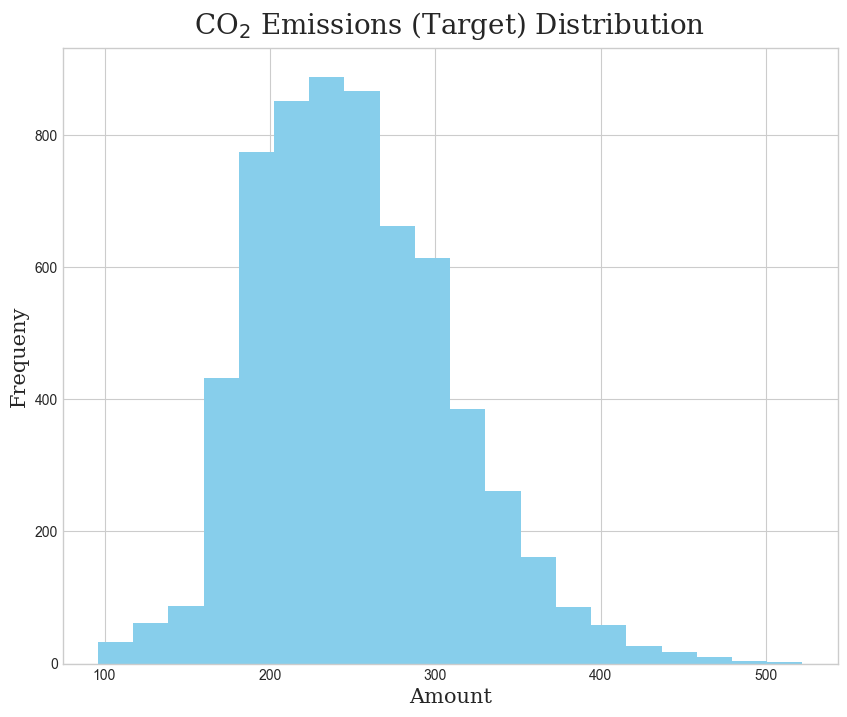

In [15]:
target.hist(bins=20, figsize=(10, 8), color='skyblue')
plt.title('CO$_2$ Emissions (Target) Distribution ', font='serif', pad=10, fontsize=20)
plt.ylabel('Frequeny', font='serif', fontsize=15)
plt.xlabel('Amount', font='serif', fontsize=15)
plt.show()

Text(0.5, 1.0, 'CO2 Emission Box Plot')

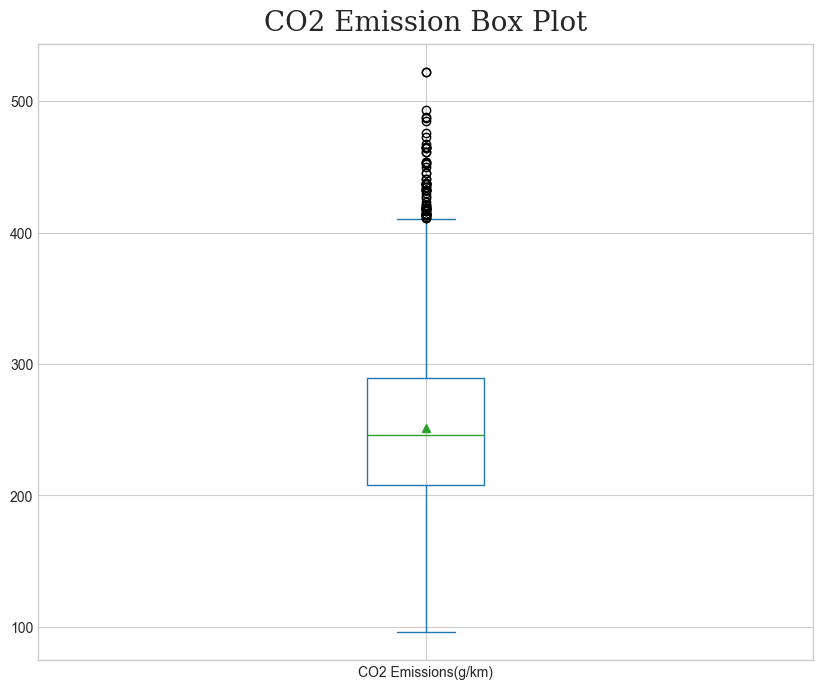

In [16]:
target.plot(kind='box', figsize=(10, 8), showmeans=True)
plt.title('CO2 Emission Box Plot', font='serif', fontsize=20, pad=10)

In [17]:
Q1 = np.quantile(target, 0.25)
Q2 = np.quantile(target, 0.5)
Q3 = np.quantile(target, 0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [18]:
outliers = target[(target < lower_bound) | (target > upper_bound)]

In [19]:
len(outliers)

74

Using the IQR method, 74 outliers were identified in the target variable. However, these values were not removed. Most of them belong to real vehicles with very high CO₂ emissions, such as supercars from manufacturers like Bugatti and Rolls-Royce, rather than being the result of data-recording errors. Therefore, these values can be considered a natural and valid part of the real-world car market distribution.

Removing these observations could restrict the range of values available to the model during training and reduce its ability to predict emissions for uncommon vehicles. In addition, the tree-based models used in this project, including Random Forest, XGBoost, Decision Tree, and Extra Trees, are generally less sensitive to outliers than linear models.

## 3.2 - Numerical Features

In [20]:
numerical = df.drop(TARGET, axis=1).select_dtypes(include='number').columns.to_list()

In [21]:
numerical

['Engine Size(L)',
 'Cylinders',
 'Fuel Consumption City (L/100 km)',
 'Fuel Consumption Hwy (L/100 km)',
 'Fuel Consumption Comb (L/100 km)',
 'Fuel Consumption Comb (mpg)']

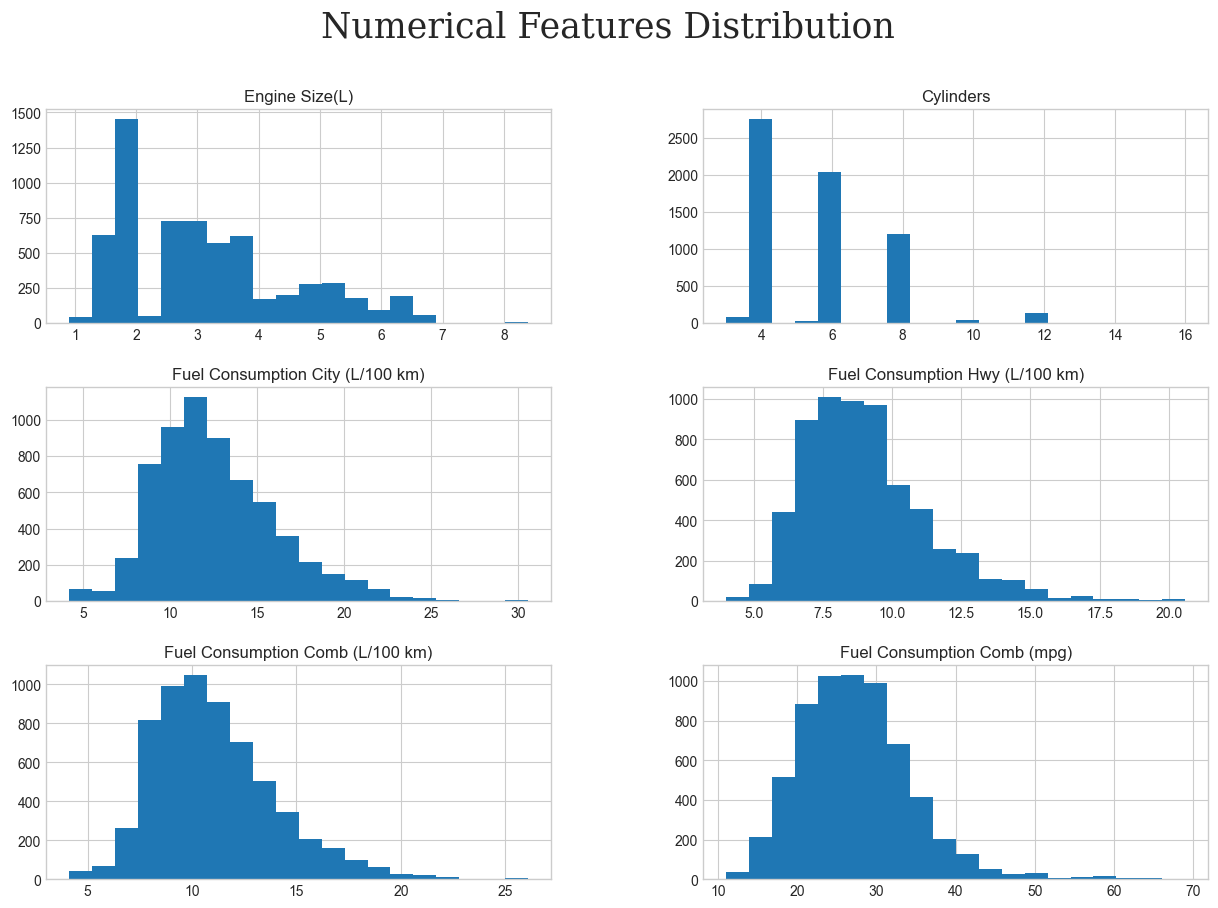

In [22]:
df[numerical].hist(bins=20, figsize=(15, 10))
plt.suptitle('Numerical Features Distribution', fontsize=25, font='serif')
plt.show()

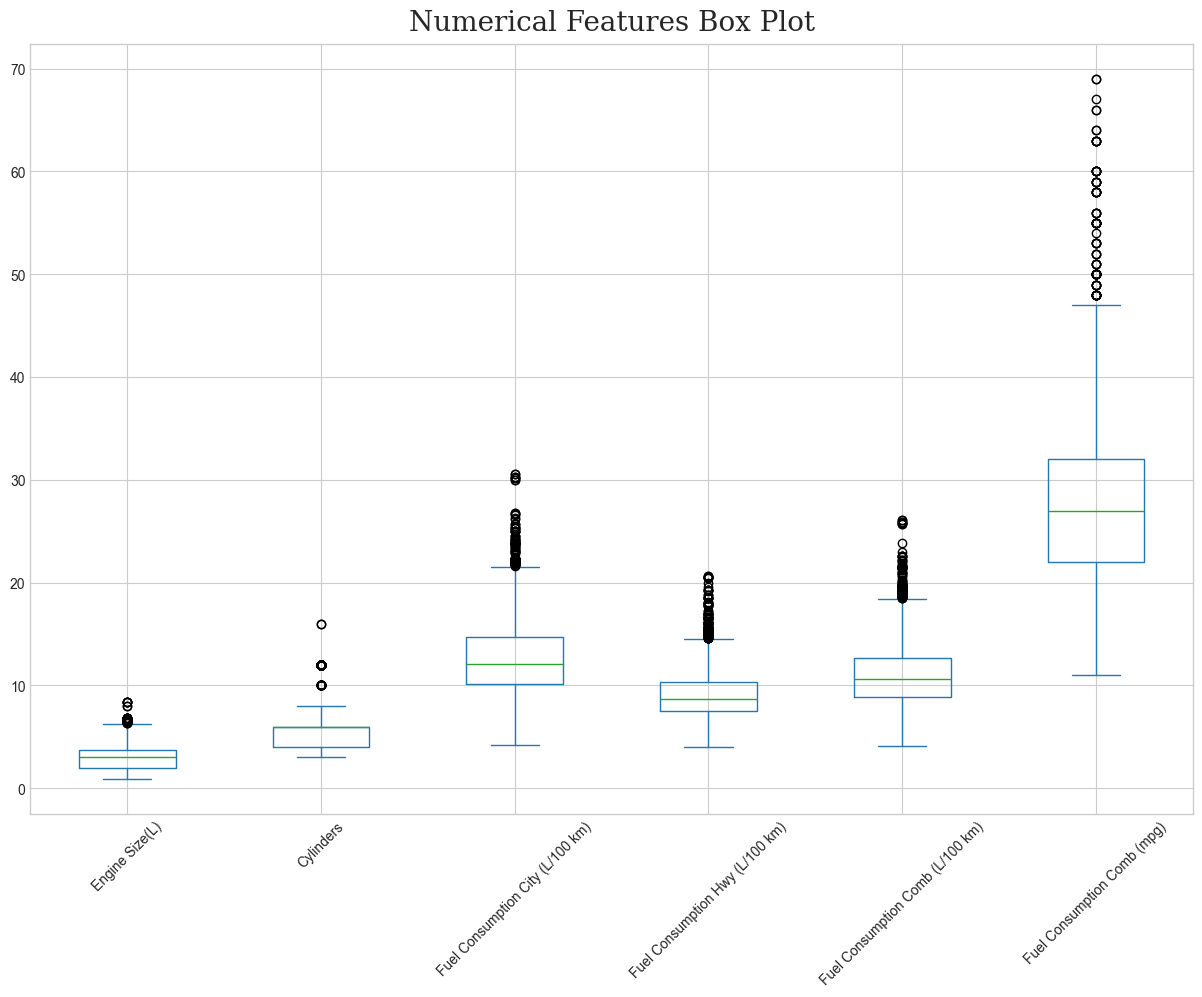

In [23]:
fig, ax = plt.subplots(figsize=(15, 10))
df[numerical].plot(kind='box', ax=ax)
ax.set_xticklabels(numerical, rotation=45)
ax.set_title('Numerical Features Box Plot', font='serif', fontsize=20, pad=10)
plt.show()

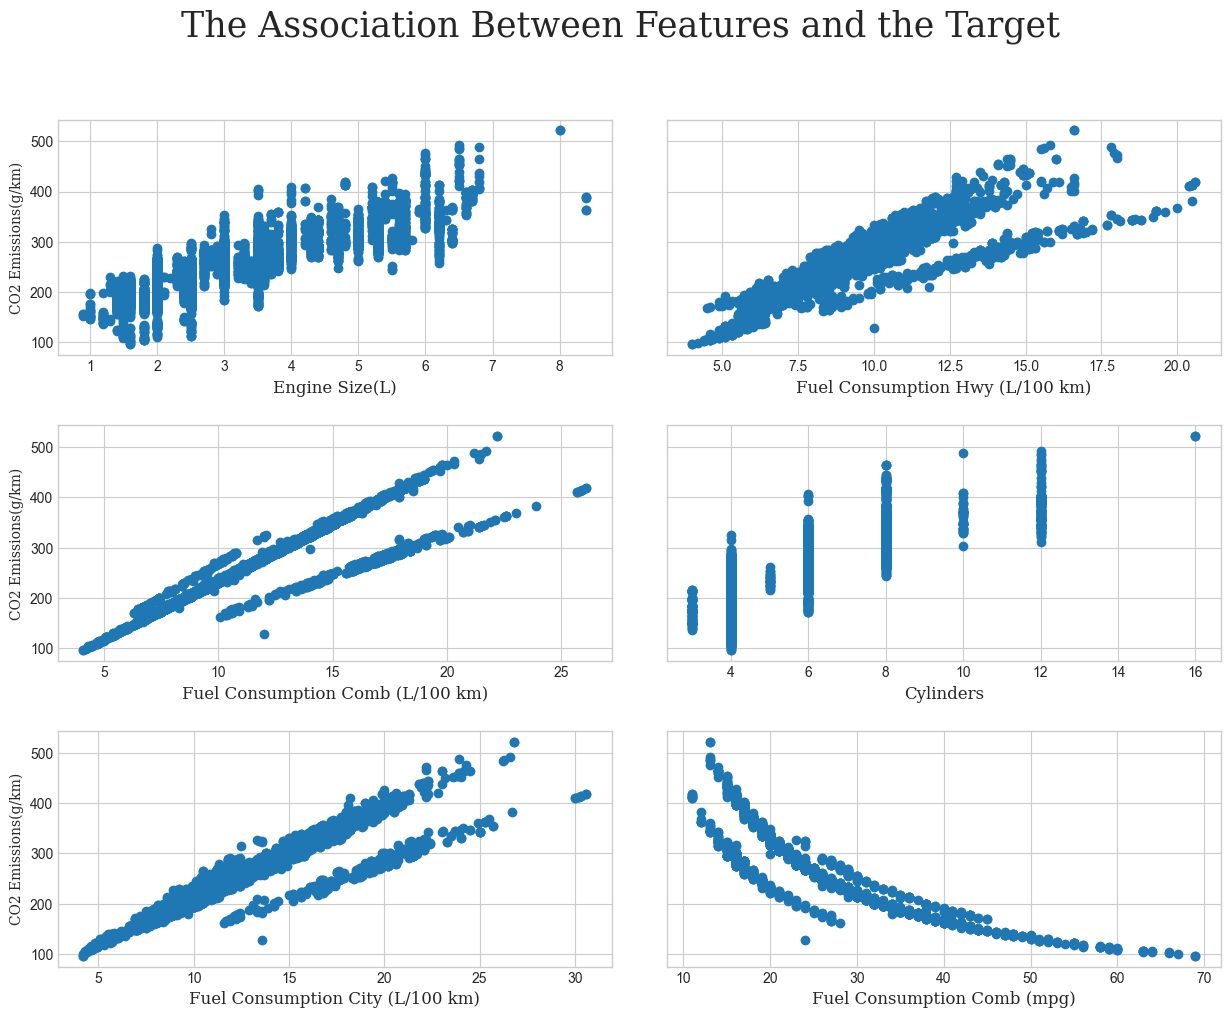

In [24]:
fig, ax = plt.subplots(3, 2, figsize=(15, 11), sharey=True)

for idx, col in enumerate(numerical):
    row = idx % 3
    column = idx % 2
    ax[row, column].scatter(df[col], df[TARGET])
    ax[row, column].set_xlabel(col, font='serif', fontsize=12)
    
for i in range(3):
    ax[i, 0].set_ylabel(TARGET, font='serif', fontsize=10)

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.suptitle('The Association Between Features and the Target', font='serif', fontsize=25)
plt.show()

In [25]:
print('Outliers:')
for col_name in numerical:
    vals = df[col_name]
    Q1 = np.quantile(vals, 0.25)
    Q2 = np.quantile(vals, 0.5)
    Q3 = np.quantile(vals, 0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = vals[(vals < lower_bound) | (vals > upper_bound)]

    print('=' * 35)
    print(f'Column name: {col_name}, NO. outliers: {len(outliers)} \n')

Outliers:
Column name: Engine Size(L), NO. outliers: 121 

Column name: Cylinders, NO. outliers: 177 

Column name: Fuel Consumption City (L/100 km), NO. outliers: 116 

Column name: Fuel Consumption Hwy (L/100 km), NO. outliers: 150 

Column name: Fuel Consumption Comb (L/100 km), NO. outliers: 115 

Column name: Fuel Consumption Comb (mpg), NO. outliers: 95 



In [26]:
VIF = pd.DataFrame()
VIF['Features'] = numerical
VIF['VIF'] = [
    variance_inflation_factor(df[numerical], i)
    for i in range(len(numerical))
]

In [27]:
VIF

,Features,VIF
0,Engine Size(L),55.149606
1,Cylinders,78.945465
2,Fuel Consumption City (L/100 km),30259.576199
3,Fuel Consumption Hwy (L/100 km),10501.080825
4,Fuel Consumption Comb (L/100 km),75440.706943
5,Fuel Consumption Comb (mpg),6.885935


The Variance Inflation Factor (VIF) measures multicollinearity between each numerical feature and the other numerical features. The VIF values for the fuel consumption columns are extremely high, ranging from 10,501 to more than 75,000, suggesting that these four columns largely contain the same information. In contrast, `Engine Size` and `Cylinders` show moderate multicollinearity, with VIF values between 55 and 79. These values are well above the commonly used thresholds of 5 or 10, but this multicollinearity is less concerning than that observed among the fuel consumption columns.

**This finding is one of the reasons for removing `Fuel Consumption Comb (mpg)` in Section 3.5.2.** The complete removal of the remaining fuel consumption columns in Section 3.6.2, however, has a separate and more important justification: these features are unavailable at inference time in the pre-production scenario (Section 1.4).


## 3.3 - Categorical Features

In [28]:
categorical = df.select_dtypes(include='object').columns.to_list()

In [29]:
categorical

['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type']

In [30]:
for col in categorical:
    group = df.groupby(col)[TARGET].agg(['mean', 'std', 'min', 'max', 'count'])
    print('=' * 55)
    print(f'Column name: {col}')
    print(group)
    print()

Column name: Make
                     mean        std  min  max  count
Make                                                 
ACURA          221.666667  30.333260  136  267     51
ALFA ROMEO     231.315789  38.208569  193  292     19
ASTON MARTIN   344.282051  32.238379  264  450     39
AUDI           252.676806  46.657577  177  409    263
BENTLEY        367.914286  41.162784  291  465     35
BMW            252.514970  43.765720  181  370    501
BUGATTI        522.000000   0.000000  522  522      2
BUICK          233.750000  32.698968  182  323     92
CADILLAC       266.141844  41.409209  203  382    141
CHEVROLET      264.477670  65.726300  121  465    515
CHRYSLER       244.046875  27.643668  181  317     64
DODGE          277.088889  45.363866  168  387    180
FIAT           192.285714  16.301382  156  226     56
FORD           261.285962  55.114745  126  488    577
GENESIS        282.571429  26.734346  238  332     14
GMC            300.529412  49.724379  198  465    289
HONDA     

Group mean computes the average value of target for each unique category in categorical feature.

Suppose the `Fuel Type` column contains five unique categories ['Z', 'D', 'X', 'E', 'N'].

Group mean computes mean of Co$_2$ Emission amount on each fuel type.

A smaple:
|Fuel Type|CO$_2$ Emission|
|---|---|
|Z|165|
|D|250|
|X|220|
|E|300|
|N|180|

The goal is to determine whether different categories are associated with different mean values of the target variable.

For each category, we compute the average traget value. 

To summarize the different between category means, we compute the standard deviation of those means. 

interpretation:

- A larger standard deviation indicates that the category means are more spread out.
- A smaller standard deviation indicates that the category means are closer to one another.
- This metric is useful for exploratory comparison only and should not be interpreted as feature importance.
- This metric ignores the number of samples in each category. Therefore, the observed differences should be validated using statistical tests such as ANOVA or information-theoretic measures such as Mutual Information.

In [31]:
for col in categorical:
    group_mean = df.groupby(col)[TARGET].agg('mean')
    group_std = group_mean.std()
    print('=' * 35)
    print(f'Column name: {col}')
    print(group_std)
    print()

Column name: Make
69.99834185444743

Column name: Model
60.81726825405879

Column name: Vehicle Class
52.58631909405066

Column name: Transmission
45.62352872986599

Column name: Fuel Type
25.46707838109561



After computing the group means, we perform a one-way ANOVA test to determine whether the observed differences between category means are statistically significant.

Hypotheses

- H₀: All category means are equal.
- H₁: At least one category has a different mean.

The test statistic is

F = Between-group variance / Within-group variance

A larger F statistic indicates that the differences between group means are large compared to the variation within each group.

Interpretation

- A small p-value (typically < 0.05) suggests that at least one category has a significantly different mean.
- ANOVA does **not** indicate which category is different.
- ANOVA does **not** measure feature importance.
- With large datasets, even small differences may become statistically significant. Therefore, ANOVA should be interpreted together with effect size, group mean analysis, mutual information, and model performance.

In [32]:
for col in categorical:
    groups = [
        group[TARGET]
        for _, group in df.groupby(col)
    ]
    f_stats, p_value = f_oneway(*groups)

    print('=' * 35)
    print(f'Column name: {col}')
    print(f'F-Stats: {round(f_stats, 2)}, P-Value: {round(p_value, 2)}')
    print()

Column name: Make
F-Stats: 89.83, P-Value: 0.0

Column name: Model
F-Stats: 46.26, P-Value: 0.0

Column name: Vehicle Class
F-Stats: 236.36, P-Value: 0.0

Column name: Transmission
F-Stats: 85.68, P-Value: 0.0

Column name: Fuel Type
F-Stats: 116.89, P-Value: 0.0



The goal of Mutual Information is not to measure importance, but to measure information.

A feature is useful if knowing its value reduces our uncertainty about the target. However, MI evaluates each feature independently and cannot determine whether that information is redundant once other features are available.


Feature selection is fundamentally the process of distinguishing informative features from features that only appear informative due to randomness or redundancy.

In [33]:
for col in categorical:
    encoder = OrdinalEncoder()

    x = encoder.fit_transform(df[[col]])

    mi = mutual_info_regression(
        x,
        df[TARGET],
        discrete_features=True
    )

    print('=' * 35)
    print(f'Column name: {col}')
    print(f'MI: {round(mi[0], 2)}')
    print()
    

C:\Users\alikh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\alikh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\alikh\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\alikh\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\alikh\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Column name: Make
MI: 0.65

Column name: Model
MI: 1.87

Column name: Vehicle Class
MI: 0.45

Column name: Transmission
MI: 0.44

Column name: Fuel Type
MI: 0.12



In [34]:
len(df['Model'].unique())

2053

In [35]:
df['Model'].value_counts()

Model
F-150 FFV             32
F-150 FFV 4X4         31
MUSTANG               27
FOCUS FFV             24
F-150 4X4             20
                      ..
LS 500                 1
LS 500h                1
NX 300 AWD F SPORT     1
RX 350 L AWD           1
XC40 T4 AWD            1
Name: count, Length: 2053, dtype: int64

## 3.4 - Correlation Analysis

<Axes: >

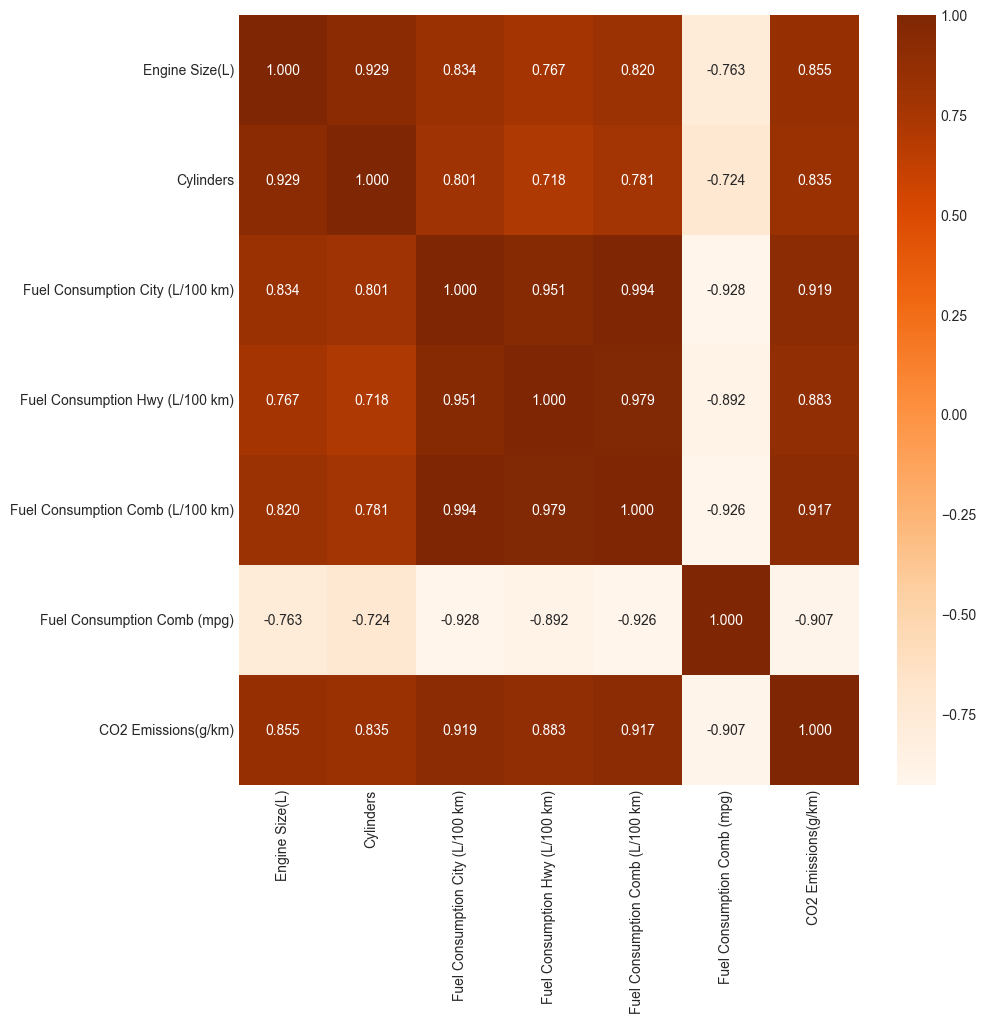

In [36]:
plt.figure(figsize=(10, 10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.3f', cmap='Oranges')

<Axes: >

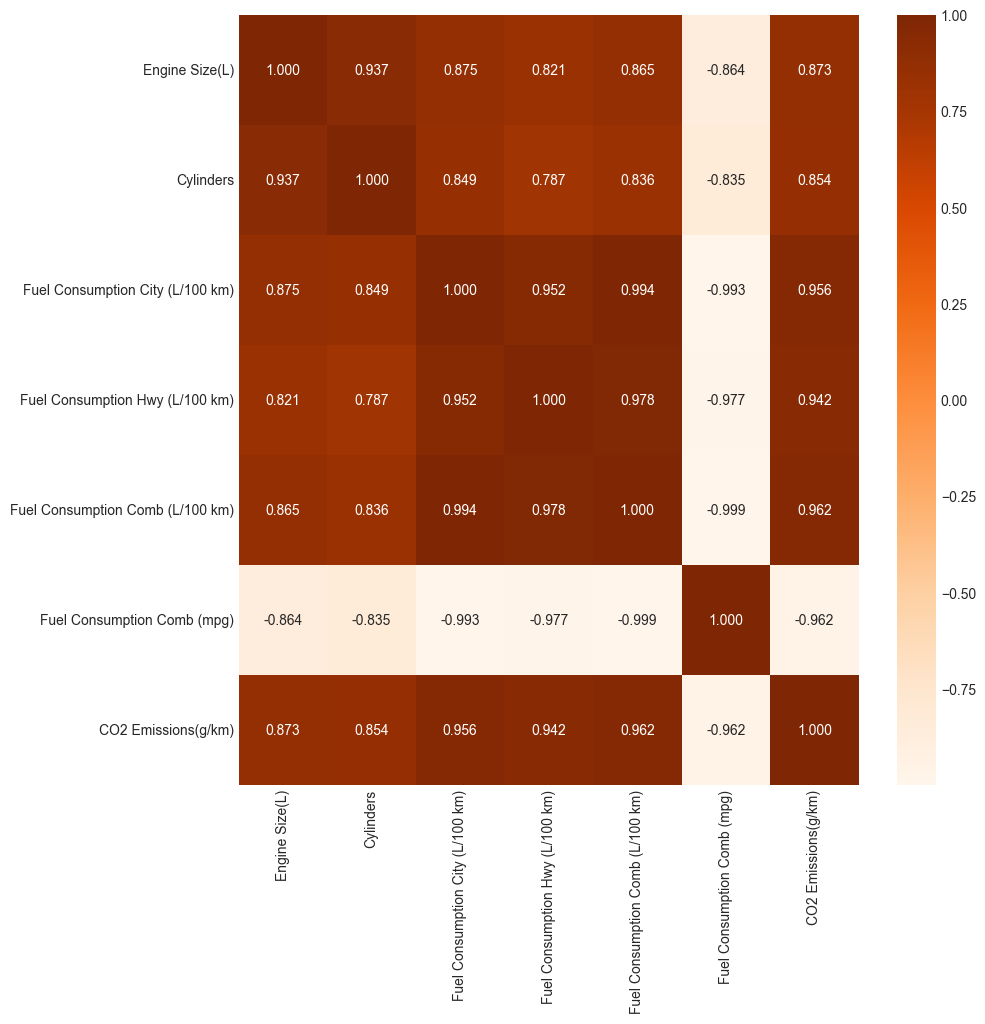

In [37]:
plt.figure(figsize=(10, 10))
corr_spearman = df.corr(numeric_only=True, method='spearman')
sns.heatmap(corr_spearman, annot=True, fmt='.3f', cmap='Oranges')

## 3.5 - Fuel Consumption Analysis

In [38]:
fuel_cols = [
    "Fuel Consumption City (L/100 km)",
    "Fuel Consumption Hwy (L/100 km)",
    "Fuel Consumption Comb (L/100 km)",
    "Fuel Consumption Comb (mpg)"
]

### 3.5.1 - Relationship with target

In [39]:
lin_corr = df[fuel_cols + [TARGET]].corr()[TARGET]

In [40]:
nonlin_corr = df[fuel_cols + [TARGET]].corr(method='spearman')[TARGET]

In [41]:
fuel_corr_comparison = pd.DataFrame(
    {
        'Pearson': lin_corr[:-1].values,
        'Spearman': nonlin_corr[:-1].values
    },
    index=lin_corr.index[:-1]
)

In [42]:
fuel_corr_comparison

,Pearson,Spearman
Fuel Consumption City (L/100 km),0.918756,0.956081
Fuel Consumption Hwy (L/100 km),0.883424,0.942182
Fuel Consumption Comb (L/100 km),0.916840,0.962399
Fuel Consumption Comb (mpg),-0.906783,-0.961680


### 3.5.2 - Redundancy Between Fuel Consumption Features

In [43]:
df[fuel_cols].corr()

,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg)
Fuel Consumption City (L/100 km),1.000000,0.950811,0.994052,-0.927640
Fuel Consumption Hwy (L/100 km),0.950811,1.000000,0.978607,-0.891892
Fuel Consumption Comb (L/100 km),0.994052,0.978607,1.000000,-0.925801
Fuel Consumption Comb (mpg),-0.927640,-0.891892,-0.925801,1.000000


In [44]:
df[fuel_cols].corr(method='spearman')

,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg)
Fuel Consumption City (L/100 km),1.000000,0.951612,0.994323,-0.993356
Fuel Consumption Hwy (L/100 km),0.951612,1.000000,0.978139,-0.977290
Fuel Consumption Comb (L/100 km),0.994323,0.978139,1.000000,-0.999010
Fuel Consumption Comb (mpg),-0.993356,-0.977290,-0.999010,1.000000


Correlation among the four `Fuel Consumption` columns is extremely high (most Spearman correlation coefficients are above 0.95, the correlation between the two `Comb` columns is -0.999); it means they are practically representing the same quantity in different units. Consequently, the `Fuel Consumption Comb (mpg)` is removed. 

This decision is separate from the main decision made in Sections 1.4 and 3.6.2.Even if the Fuel Consumption columns were permissible under the project scenario, keeping both `Comb` versions would not provide additional information.

In [45]:
fuel_cons_mgp = 'Fuel Consumption Comb (mpg)'

df = df.drop(columns=fuel_cons_mgp)

In [46]:
df.columns

Index(['Make', 'Model', 'Vehicle Class', 'Engine Size(L)', 'Cylinders',
       'Transmission', 'Fuel Type', 'Fuel Consumption City (L/100 km)',
       'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
       'CO2 Emissions(g/km)'],
      dtype='object')

## 3.6 - Feature Selection Consideration

### 3.6.1 - High-cardinality Model

Despite the high MI of `Model` (Section 3.3),this feature is removed; there are 2,053 unique Model values across only 6,282 records. In other words, fewer than three samples per unique Model value, on average. Applying OneHotEncoder to this feature would significantly increase the number of columns and the risk of overfitting. As a result, the model may not be able to learn generalizable patterns from these rare categories.

In [47]:
model_faeture_to_remove = 'Model'

In [48]:
df = df.drop(columns=model_faeture_to_remove)

In [49]:
df.columns

Index(['Make', 'Vehicle Class', 'Engine Size(L)', 'Cylinders', 'Transmission',
       'Fuel Type', 'Fuel Consumption City (L/100 km)',
       'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
       'CO2 Emissions(g/km)'],
      dtype='object')

### 3.6.2 - Inference-Time Feature Availability

As stated in Section 1.4, The decision to remove the `Fuel Consumption` was made based on the pre-production scenario.

The following tabel formally shows this decision for each features individually.

|Features|Available at inference|Reason|
|:---:|:---:|:---:|
|Make|✓|Vehicle specification|
|Model|✓|Vehicle specification|
|Vehicle Class|✓|Vehicle specification|
|Engine Size|✓|Vehicle specification|
|Cylinders|✓|Vehicle specification|
|Fuel Type|✓|Vehicle specification|
|Transmission|✓|Vehicle specification|
|Vehicle Class|✓|Vehicle specification|
|Fuel Consumption City|✗|Requires vehicle testing|
|Fuel Consumption Hwy|✗|Requires vehicle testing|
|Fuel Consumption Comb|✗|Requires vehicle testing|

In [50]:
fuel_cols_to_reomve = [
    'Fuel Consumption City (L/100 km)',
    'Fuel Consumption Hwy (L/100 km)',
    'Fuel Consumption Comb (L/100 km)'
]

In [51]:
df = df.drop(columns=fuel_cols_to_reomve)

In [52]:
df.columns

Index(['Make', 'Vehicle Class', 'Engine Size(L)', 'Cylinders', 'Transmission',
       'Fuel Type', 'CO2 Emissions(g/km)'],
      dtype='object')

# 4 - Feature Engineering

The goal of this section is to test whether combining the two available numerical features, `Engine Size` and `Cylinders`, can provide a new signal for predicting CO₂ emissions that neither feature provides individually. Two candidate engineered features are defined and tested:

* **Cylinders-to-Engine-Size ratio** (`Cylinders / Engine Size`), which can be roughly interpreted as a proxy for “specific power” or design efficiency.
* **Cylinders × Engine Size**, which represents the overall engine size through a combined measure of the two features.

To avoid making a decision based solely on intuition, both features are evaluated using cross-validation with XGBoost in an experimental pipeline, and the results are compared with the baseline without any additional engineered features.

This experiment is completely independent of the final pipeline in Section 5 and is used solely to determine which feature, if any, should be included in the final model.


In [53]:
numerical_features = df.drop(columns=TARGET).select_dtypes(include='number').columns.to_list()
categorical_features = df.select_dtypes(include='object').columns.to_list()

In [54]:
X_for_test = df.drop(columns=TARGET)
y_for_test = df[TARGET]

In [55]:
X_for_test_train, X_for_test_test, y_for_test_train, y_for_test_test = train_test_split(
    X_for_test,
    y_for_test,
    test_size=0.2,
    stratify=df['Make'],
    random_state=RANDOM_STATE
)

In [2]:
def add_cylinder_engine_ratio(X):
    if not isinstance(X, pd.DataFrame):
        raise TypeError('X must be a pandas DataFrame.')
    X = X.copy()
    X['Cylinder_pre_liter'] = X['numeric__Cylinders'] / X['numeric__Engine Size(L)']
    return X

def add_engine_cylinder_product(X):
    if not isinstance(X, pd.DataFrame):
        raise TypeError('X must be a pandas DataFrame.')
    X = X.copy()
    X['Engine_Cylinder_product'] = X['numeric__Engine Size(L)'] * X['numeric__Cylinders']
    return X

In [57]:
def build_test_preprocessor(*, numerical, categorical):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                'ohe', 
                 OneHotEncoder(
                     handle_unknown='ignore',
                     sparse_output=False
                ), 
                categorical
            ),
            (
                'numeric',
                'passthrough',
                 numerical
            )
        ]
    )

    return preprocessor

In [58]:
model_for_test = XGBRegressor(random_state=RANDOM_STATE)

In [59]:
preprocessor = build_test_preprocessor(numerical=numerical_features,
                                      categorical=categorical_features)

In [60]:
test_pipeline1 = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('scaler', StandardScaler()),
        ('model', model_for_test)
    ]
)


test_pipeline2 = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('feature_set1', FunctionTransformer(add_cylinder_engine_ratio, validate=False)),
        ('scaler', StandardScaler()),
        ('model', model_for_test)
    ]
)

test_pipeline3 = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('feature_set1', FunctionTransformer(add_cylinder_engine_ratio, validate=False)),
        ('feature_set2', FunctionTransformer(add_engine_cylinder_product, validate=False)),
        ('scaler', StandardScaler()),
        ('model', model_for_test)
    ]
)

test_pipelines = [
    test_pipeline1,
    test_pipeline2,
    test_pipeline3
]

names = [
    'Raw',
    '+ CYL / ENG',
    '+ CYL * ENG'
]

In [61]:
print('Result: ')
for name, pipeline in zip(names, test_pipelines):

    scores = -cross_val_score(
        pipeline,
        X_for_test_train,
        y_for_test_train,
        scoring='neg_root_mean_squared_error',
        cv=5,
        n_jobs=-1
    )

    result = {
        'Mean': scores.mean(),
        'STD': scores.std(),
        'Median': np.median(scores),
        'Min': scores.min(),
        'Max': scores.max()
    }
    print('=' * 35)
    print(f'Nmae: {name}')
    print(result)
    print()
    


Result: 
Nmae: Raw
{'Mean': 14.250390434265137, 'STD': 0.1609144645435749, 'Median': 14.294182777404785, 'Min': 13.9907865524292, 'Max': 14.422428131103516}

Nmae: + CYL / ENG
{'Mean': 14.110101890563964, 'STD': 0.3508684843295647, 'Median': 14.061493873596191, 'Min': 13.523261070251465, 'Max': 14.52289867401123}

Nmae: + CYL * ENG
{'Mean': 14.236027717590332, 'STD': 0.26707050279651673, 'Median': 14.32515811920166, 'Min': 13.806108474731445, 'Max': 14.527555465698242}



The results show that including `CYL / ENG` reduce mean cross-validation RSME from 14.25 to 14.11, representing a small but positive improvement. In contrast, `CYL * ENG` shows performance nearly identical to the baseline (`Raw`) (14.24 vs. 14.25). This difference negligable relative to the standard deviation across folds ($\approx{0.27}$), suggesting that it does not provide a reliable additional signal.

Accordingly, the ratio feature (`cylider per liter`) is inculded in the final pipeline (Section 5, `build_features` function), while the product feature is excluded.

# 5 - Data Preprocessing

In [62]:
numerical_features = df.drop(columns=TARGET).select_dtypes(include='number').columns.to_list()
categorical_features = df.select_dtypes(include='object').columns.to_list()

In [63]:
numerical_features

['Engine Size(L)', 'Cylinders']

In [64]:
categorical_features

['Make', 'Vehicle Class', 'Transmission', 'Fuel Type']

In [65]:
X = df.drop(columns=TARGET)
y = df[TARGET]

In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2,
    stratify=df['Make'],
    random_state=RANDOM_STATE
)

The data were split into train and test using `stratify=df['Make']` to keep the distribution of manufacturers (`Make`) in both the training and test sets similar to that of the full dataset. This helps prevent a situation in which a particular manufacturer with its own range of CO₂ emissions, is disproportionately represented in only one of the two sets, which could introduce bias into model evaluation.

It is worth noting that some manufacturers have very few records in the dataset, such as Bugatti and SRT. Stratified splitting can still be applied to these low-frequency classes, although their representation in the resulting split is less precise than that of more frequent classes. This limitation is discussed in Section 13 (`Conclusions & Limitations`).

In [67]:
def build_features(X, prefix='numeric'):
    if not isinstance(X, pd.DataFrame):
        raise TypeError('X must be a pandas DataFrame.')
    X = X.copy()
    X['Cylinder_pre_liter'] = X[f'{prefix}__Cylinders'] / X[f'{prefix}__Engine Size(L)']
    return X

In [68]:
def build_preprocessor(*, numerical, categorical):
    cat_prefix = 'ohe'
    num_prefix = 'numeric'
    preprocessor = ColumnTransformer(
        transformers=[
            (
                cat_prefix,
                OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                categorical
            ),
            (
                num_prefix,
                'passthrough',
                numerical
            )
        ]
    )

    return preprocessor

In [69]:
def build_pipeline(*, preprocessor, feature_builder, model=None):
    if model is not None:
        steps =  [
            (
                'preprocess', 
                preprocessor
            ),
            (
                'feature_eng',
                FunctionTransformer(
                    feature_builder,
                    validate=False
                )
            ),
            (
                'sacler',
                StandardScaler()
            ),
            (
                'model',
                model
            )
        ]
    else:
        steps =  [
            (
                'preprocess', 
                preprocessor
            ),
            (
                'feature_eng',
                FunctionTransformer(
                    feature_builder,
                    validate=False
                )
            ),
            (
                'sacler',
                StandardScaler()
            )
        ]
        
    pipeline = Pipeline(
       steps
    )

    return pipeline

In [70]:
preprocessor = build_preprocessor(categorical=categorical_features, numerical=numerical_features)

# 6 - Baseline Models

In [71]:
models = {
    "LR": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Elastic": ElasticNet(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42)
}

In [72]:
bl_cv_results = {}

In [73]:
n_cv = 10

In [74]:
for name, model in models.items():
    scores = -cross_val_score(
        build_pipeline(
            preprocessor=preprocessor,
            feature_builder=build_features,
            model=model
        ),
        X_train,
        y_train,
        scoring='neg_root_mean_squared_error',
        cv=n_cv
    )

    bl_cv_results[name] = scores

In [75]:
bl_res = pd.DataFrame(bl_cv_results).T

In [76]:
bl_res.columns = [f'Fold {i}' for i in range(1, n_cv + 1)]

In [77]:
bl_res

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Fold 6,Fold 7,Fold 8,Fold 9,Fold 10
LR,19.175415,21.803167,20.383047,18.381211,20.083033,21.294922,18.543941,19.608700,19.789497,21.122396
Ridge,19.174052,21.803055,20.382686,18.380555,20.083126,21.292756,18.543686,19.609477,19.788957,21.123630
Lasso,21.121964,23.314704,22.154590,19.450366,22.049927,22.471837,20.720788,22.116493,21.118404,23.731289
Elastic,22.023798,25.514774,24.383153,21.333484,24.043168,24.210020,22.490722,24.319675,22.984738,26.181460
Decision Tree,13.348427,12.970972,14.481047,13.740518,16.050360,14.297764,13.769311,14.249499,13.757534,14.921539
Random Forest,13.136881,12.882318,13.307938,13.381293,14.337811,14.399766,13.054617,14.052124,13.300051,14.840473
XGBoost,13.302887,13.019980,13.742479,13.584792,13.777048,14.768962,12.495567,14.152821,12.897733,14.727719
Extra Trees,13.457276,12.548097,13.629309,13.554536,14.146076,14.436736,13.191523,13.943363,13.020201,15.016749


# 7 - Baseline Model Comparison

In [78]:
print('Baseline results conclusion: ')
for name, scores in bl_cv_results.items():
    mean = scores.mean()
    std = scores.std()
    mdian = np.median(scores)
    minimum = scores.min()
    maximum = scores.max()
    print('=' * 60)
    print(f'Name: {name}')
    print(f'Mean: {mean:.2f}, SD: {std:.2f}, Mdian: {mdian:.2f}, Min: {minimum:.2f}, Max: {maximum:.2f}')
    print()

Baseline results conclusion: 
Name: LR
Mean: 20.02, SD: 1.09, Mdian: 19.94, Min: 18.38, Max: 21.80

Name: Ridge
Mean: 20.02, SD: 1.09, Mdian: 19.94, Min: 18.38, Max: 21.80

Name: Lasso
Mean: 21.83, SD: 1.20, Mdian: 22.08, Min: 19.45, Max: 23.73

Name: Elastic
Mean: 23.75, SD: 1.45, Mdian: 24.13, Min: 21.33, Max: 26.18

Name: Decision Tree
Mean: 14.16, SD: 0.83, Mdian: 14.01, Min: 12.97, Max: 16.05

Name: Random Forest
Mean: 13.67, SD: 0.64, Mdian: 13.34, Min: 12.88, Max: 14.84

Name: XGBoost
Mean: 13.65, SD: 0.71, Mdian: 13.66, Min: 12.50, Max: 14.77

Name: Extra Trees
Mean: 13.69, SD: 0.68, Mdian: 13.59, Min: 12.55, Max: 15.02



The comparison of the baseline models, without hyperparameter tuning, demonstrates two clear patterns.

First, the linear models (LR, Ridge, Lasso, and Elastic Net), with mean RMSE values ranging from 20 to 24, perform noticeably worse than the tree-based models. This suggests that simple linear models may not adequately capture the relationships between the features and the target variable, particularly when dealing with high-cardinality categorical features such as `Make`. The underlying relationships may include nonlinear patterns that are not well captured by these linear models.

Second, among the tree-based models, the performance differences between Decision Tree, Random Forest, XGBoost, and Extra Trees are very small in the baseline setting, with mean RMSE values ranging from 13.65 to 14.16. This small difference suggests that the final model should not be selected solely based on the baseline results. Consequently, all four tree-based models, rather than only the best-performing one, will be included in the hyperparameter tuning process so that the final decision can be made after each model has been fully tuned.

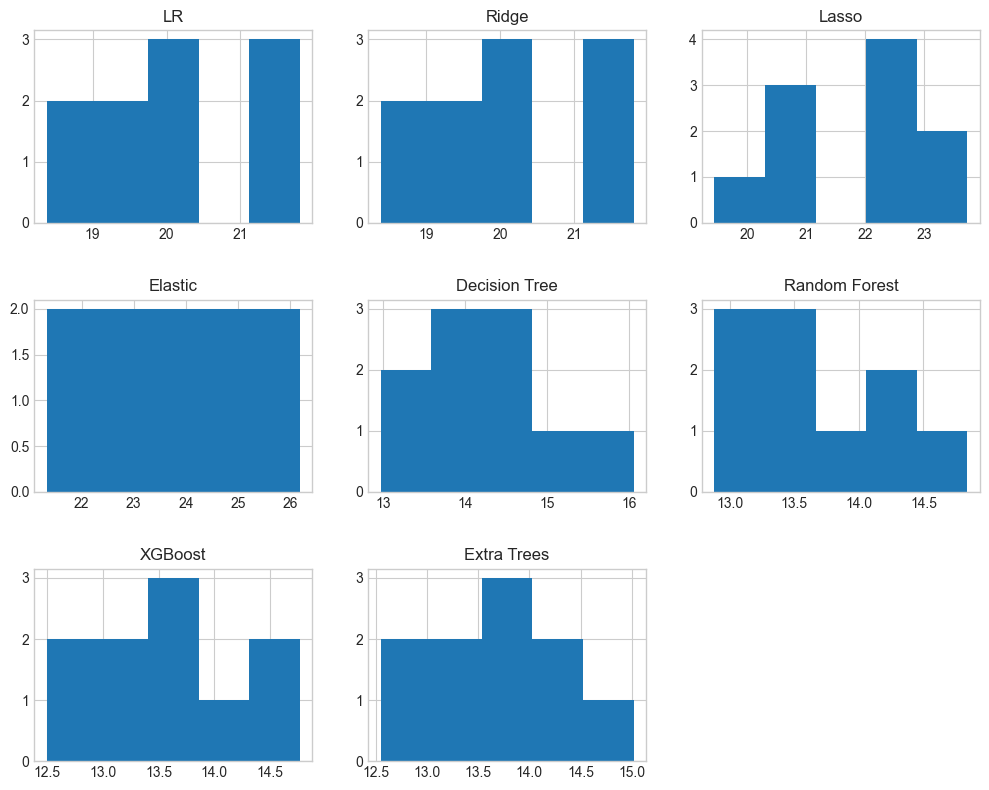

In [79]:
bl_res.T.hist(bins=5, figsize=(10, 8))
plt.tight_layout()
plt.subplots_adjust(hspace=0.4, wspace=0.2)
plt.show()

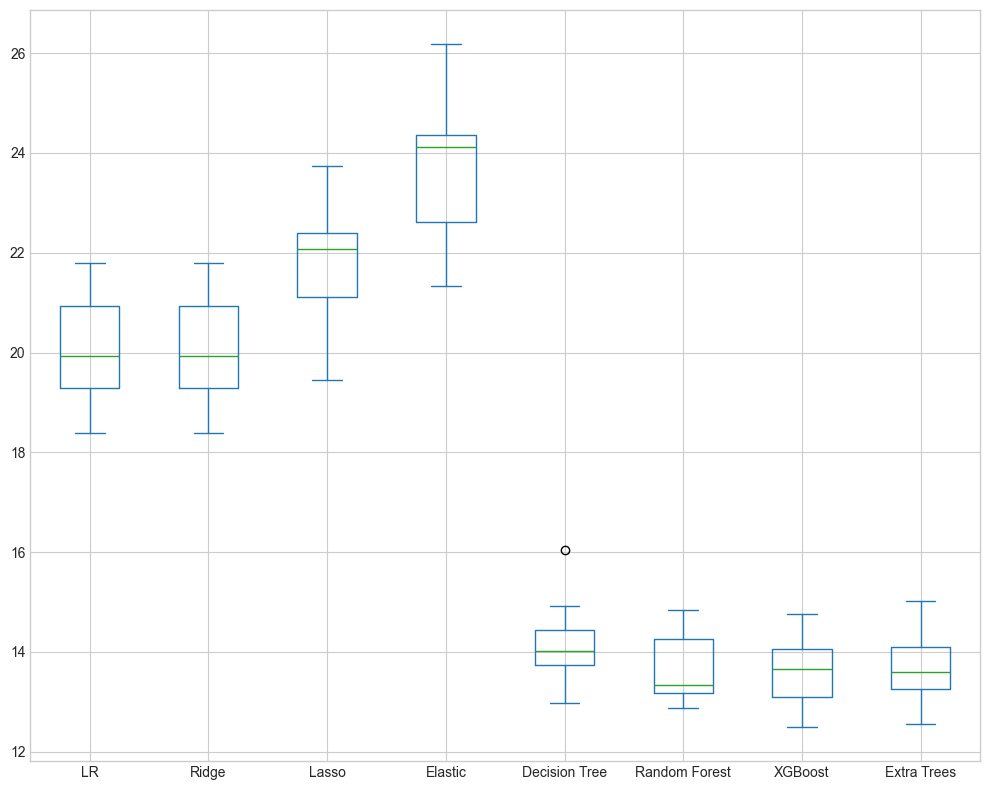

In [80]:
bl_res.T.plot(kind='box', figsize=(10, 8))
plt.tight_layout()
plt.show()

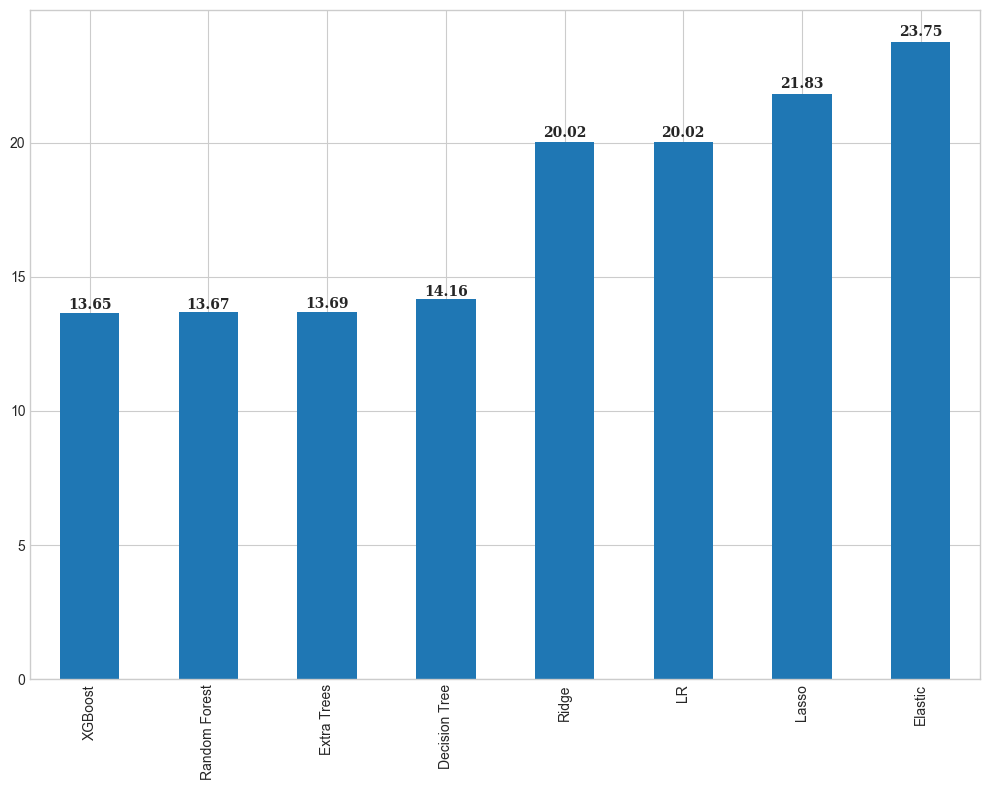

In [81]:
means = bl_res.T.mean().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 8))
means.plot(kind='bar', ax=ax)
for idx, mean in enumerate(means):
    ax.text(
        idx, 
        mean * 1.01, 
        f'{mean:.2f}',
        font='serif',
        weight='bold',
        ha='center'
    )
plt.tight_layout()
plt.show()

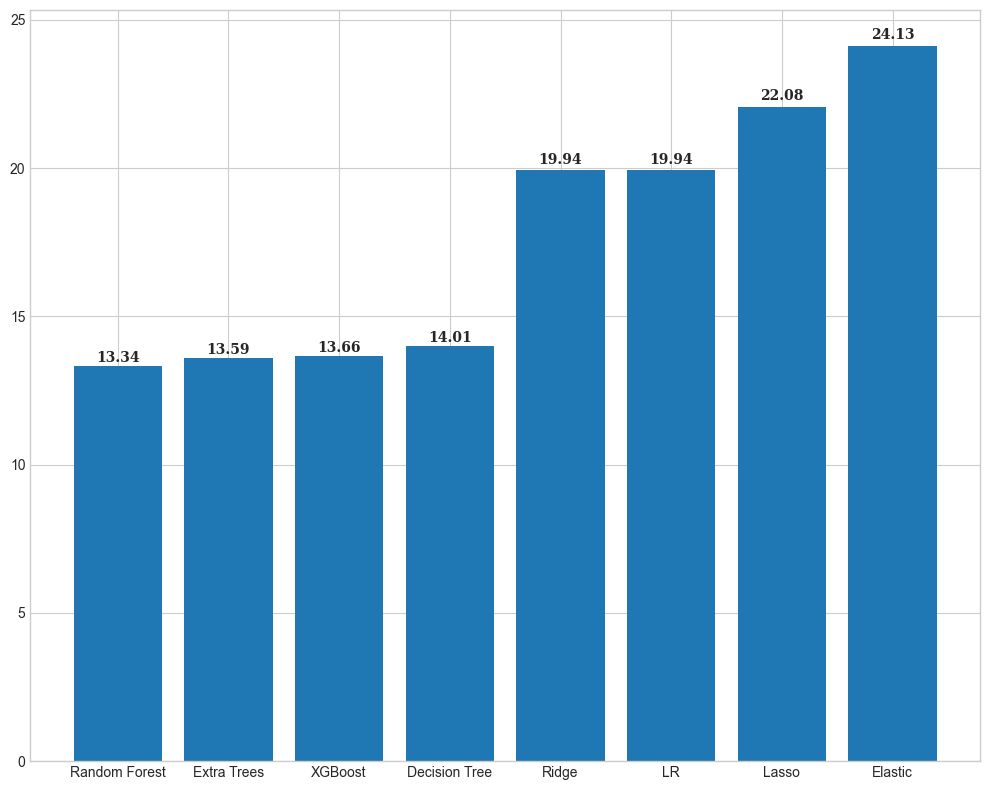

In [82]:
medians = {name: np.median(vals) for name, vals in bl_cv_results.items()}
medians = sorted(
    medians.items(),
    key=lambda item: item[1]              
)
medians = {name: round(val, 2) for name, val in medians}


fig, ax = plt.subplots(figsize=(10, 8))
ax.bar(medians.keys(), medians.values())

for idx, val in enumerate(medians.values()):
    ax.text(
        idx,
        val * 1.01,
        val,
        font='serif',
        weight='bold',
        ha='center'
    )    

plt.tight_layout()
plt.show()

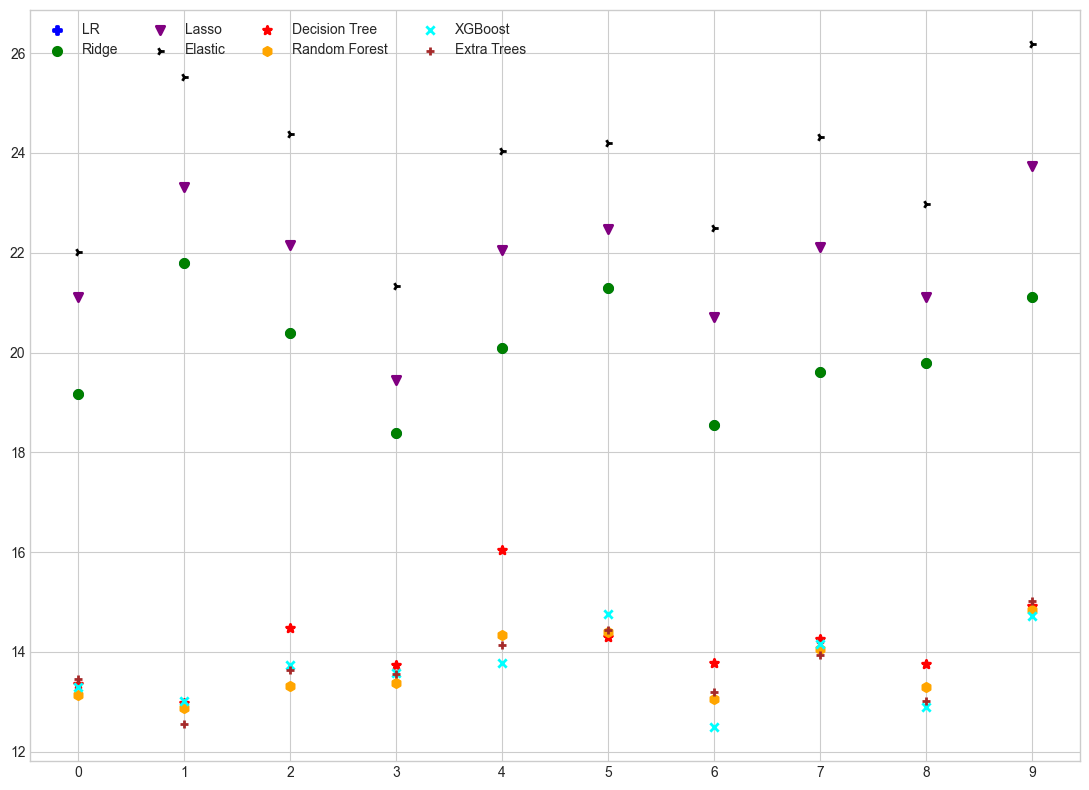

In [83]:
fig, ax = plt.subplots(figsize=(11, 8))
markers = ['P', 'o', 'v', '4', '*', 'h', 'x', '+']
colors = ['blue', 'green', 'purple', 'black', 'red', 'orange', 'cyan', 'brown']

for (name, values), marker, color in zip(bl_cv_results.items(), markers, colors):
    ax.scatter(
        range(n_cv),
        values,
        marker=marker,
        color=color,
        label=name,
        lw=2
    )
ax.set_xticks(range(n_cv))
ax.legend(ncols=len(bl_cv_results) / 2)
plt.tight_layout()
plt.show()

# 8 - Hyperparameter Optimization

In [84]:
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE
)

## 8.1 - Random Forest

In [85]:
rf_model = RandomForestRegressor(random_state=RANDOM_STATE)

In [86]:
param_dist_rf = {
    "model__n_estimators": [100, 200, 300, 500],

    "model__max_depth": [
        None,
        10,
        20,
        30,
        50
    ],

    "model__min_samples_split": [
        2,
        5,
        10
    ],

    "model__min_samples_leaf": [
        1,
        2,
        4
    ],

    "model__max_features": [
        "sqrt",
        "log2",
        None
    ],

    "model__bootstrap": [
        True,
        False
    ]
}

In [87]:
search_rf = RandomizedSearchCV(
    estimator=build_pipeline(
        preprocessor=preprocessor,
        feature_builder=build_features,
        model=rf_model
    ),
    param_distributions=param_dist_rf,
    n_iter=50,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2
)

In [88]:
search_rf.fit(X_train, y_train)

Fitting 15 folds for each of 50 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__bootstrap': [True, False], 'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the vario

In [89]:
best_rf = search_rf.best_estimator_

In [90]:
search_rf.best_params_

{'model__n_estimators': 500,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 1,
 'model__max_features': 'sqrt',
 'model__max_depth': None,
 'model__bootstrap': False}

In [91]:
# best_rf = build_pipeline(
#     preprocessor=preprocessor,
#     model=RandomForestRegressor(
#         n_estimators=500,
#         min_samples_split=2,
#         min_samples_leaf=1,
#         max_features='sqrt',
#         max_depth=None,
#         bootstrap=False,
#         random_state=RANDOM_STATE
#     ),
#     feature_builder=build_features
# )

In [92]:
# best_rf.fit(X_train, y_train)

## 8.2 - XGB

In [93]:
xgb_model = XGBRegressor(random_state=RANDOM_STATE)

In [94]:
param_dist_xgb = {
    "model__n_estimators": [
        100,
        200,
        300,
        500
    ],

    "model__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1
    ],

    "model__max_depth": [
        2,
        3,
        5,
        7,
        10
    ],

    "model__min_child_weight": [
        1,
        3,
        5,
        10
    ],

    "model__subsample": [
        0.6,
        0.8,
        1.0
    ],

    "model__colsample_bytree": [
        0.6,
        0.8,
        1.0
    ],

    "model__gamma": [
        0,
        0.1,
        0.3,
        0.5
    ],

    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        1
    ],

    "model__reg_lambda": [
        1,
        5,
        10
    ]
}

In [95]:
search_xgb = RandomizedSearchCV(
    estimator=build_pipeline(
        preprocessor=preprocessor,
        feature_builder=build_features,
        model=xgb_model
    ),
    param_distributions=param_dist_xgb,
    n_iter=50,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2
)

In [96]:
search_xgb.fit(X_train, y_train)

Fitting 15 folds for each of 50 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.6, 0.8, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscro

In [97]:
best_xgb = search_xgb.best_estimator_

In [98]:
search_xgb.best_params_

{'model__subsample': 0.8,
 'model__reg_lambda': 1,
 'model__reg_alpha': 0.1,
 'model__n_estimators': 500,
 'model__min_child_weight': 1,
 'model__max_depth': 10,
 'model__learning_rate': 0.03,
 'model__gamma': 0,
 'model__colsample_bytree': 0.6}

In [99]:
# best_xgb = build_pipeline(
#     preprocessor=preprocessor,
#     model= XGBRegressor(
#         n_estimators=500,
#         subsample=0.8,
#         min_child_weight=1,
#         max_depth=10,
#         learning_rate=0.03,
#         gamma=0,
#         reg_lambda=1,
#         reg_alpha=1,
#         colsample_bytree=0.6,
#         random_state=RANDOM_STATE
#     ),
#     feature_builder=build_features
# )

In [100]:
# best_xgb.fit(X_train, y_train)

## 8.3 - Extra Trees

In [101]:
et_model = ExtraTreesRegressor(random_state=RANDOM_STATE)

In [102]:
param_dist_et = {
    "model__n_estimators": [
        100,
        200,
        300,
        500
    ],

    "model__max_depth": [
        None,
        10,
        20,
        30,
        50
    ],

    "model__min_samples_split": [
        2,
        5,
        10
    ],

    "model__min_samples_leaf": [
        1,
        2,
        4,
        8
    ],

    "model__max_features": [
        "sqrt",
        "log2",
        None,
        0.5,
        0.8
    ],

    "model__bootstrap": [
        False,
        True
    ],

    "model__criterion": [
        "squared_error",
        "absolute_error"
    ]
}

In [103]:
search_et = RandomizedSearchCV(
    estimator=build_pipeline(
        preprocessor=preprocessor,
        feature_builder=build_features,
        model=et_model
    ),
    param_distributions=param_dist_et,
    n_iter=50,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2
)

In [104]:
search_et.fit(X_train, y_train)

Fitting 15 folds for each of 50 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__bootstrap': [False, True], 'model__criterion': ['squared_error', 'absolute_error'], 'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guid

In [105]:
best_et = search_et.best_estimator_

In [106]:
search_et.best_params_

{'model__n_estimators': 200,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 1,
 'model__max_features': 'sqrt',
 'model__max_depth': 30,
 'model__criterion': 'squared_error',
 'model__bootstrap': True}

In [107]:
# best_et = build_pipeline(
#     preprocessor=preprocessor,
#     model=ExtraTreesRegressor(
#         n_estimators=200,
#         min_samples_split=2,
#         min_samples_leaf=1,
#         max_features='sqrt',
#         max_depth=30,
#         criterion='squared_error',
#         bootstrap=True,
#         random_state=RANDOM_STATE
#     ),
#     feature_builder=build_features
# )

In [108]:
# best_et.fit(X_train, y_train)

## 8.4 - Decision Tree

In [109]:
dt_model = DecisionTreeRegressor(random_state=RANDOM_STATE)

In [110]:
param_dist_dt = {
    "model__max_depth": [
        None,
        3,
        5,
        7,
        10,
        15,
        20,
        30
    ],

    "model__min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "model__min_samples_leaf": [
        1,
        2,
        4,
        8
    ],

    "model__max_features": [
        1.0,
        "sqrt",
        "log2"
    ],

    "model__criterion": [
        "squared_error",
        "friedman_mse",
        "absolute_error"
    ]
}

In [111]:
search_dt = RandomizedSearchCV(
    estimator=build_pipeline(
        preprocessor=preprocessor,
        feature_builder=build_features,
        model=dt_model
    ),
    param_distributions=param_dist_dt,
    n_iter=50,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2
)

In [112]:
search_dt.fit(X_train, y_train)

Fitting 15 folds for each of 50 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__criterion': ['squared_error', 'friedman_mse', ...], 'model__max_depth': [None, 3, ...], 'model__max_features': [1.0, 'sqrt', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User 

In [113]:
best_dt = search_dt.best_estimator_

In [114]:
search_dt.best_params_

{'model__min_samples_split': 5,
 'model__min_samples_leaf': 1,
 'model__max_features': 1.0,
 'model__max_depth': 20,
 'model__criterion': 'squared_error'}

In [115]:
# best_dt = build_pipeline(
#     preprocessor=preprocessor,
#     model=DecisionTreeRegressor(
#         max_depth=20,
#         min_samples_split=5,
#         min_samples_leaf=1,
#         max_features=1,
#         criterion='squared_error',
#         random_state=RANDOM_STATE
#     ),
#     feature_builder=build_features
# )

In [116]:
# best_dt.fit(X_train, y_train)

# 9 - Optimized Model Evaluation

In [288]:
metrics = {
    'R2':r2_score,
    'MAE':mean_absolute_error,
    'RMSE':root_mean_squared_error
}

In [289]:
def evaluate_model(*, model, X_train, X_test, y_train, y_test, metrics):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    model_results = {
        "Train": {},
        "Test": {}
    }

    for name, metric in metrics.items():
        model_results['Train'][name] = np.round(
            metric(y_train, y_pred_train),
            3
        )
        model_results['Test'][name] = np.round(
            metric(y_test, y_pred_test),
            3
        )
    
    return model_results

## 9.1 - Random Forest 

In [290]:
rf_results = evaluate_model(
    model=best_rf,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    metrics=metrics
)

In [291]:
pd.DataFrame(rf_results)

,Train,Test
R2,0.970,0.948
MAE,6.808,9.365
RMSE,10.308,13.444


## 9.2 - XGB

In [292]:
xgb_results = evaluate_model(
    model=best_xgb,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    metrics=metrics)

In [293]:
pd.DataFrame(xgb_results)

,Train,Test
R2,0.968,0.950
MAE,7.486,9.311
RMSE,10.666,13.163


## 9.3 - Extra Trees

In [294]:
et_results = evaluate_model(
    model=best_et,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    metrics=metrics
)

In [295]:
pd.DataFrame(et_results)

,Train,Test
R2,0.968,0.946
MAE,7.484,9.518
RMSE,10.696,13.618


## 9.4 - Decision Tree

In [296]:
dt_results = evaluate_model(
    model=best_dt,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    metrics=metrics)

In [297]:
pd.DataFrame(dt_results)

,Train,Test
R2,0.967,0.945
MAE,7.418,9.705
RMSE,10.826,13.728


# 10 - Model Diagnostics

## 10.1 - Leanring Curve

In [130]:
def plot_learning_curve(model, X, y, model_name):
    train_sizes, train_scores, validation_scores = learning_curve(
        model,
        X,
        y,
        cv=n_cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(train_sizes, -train_scores.mean(axis=1), color='blue', label='Train')
    ax.plot(train_sizes, -validation_scores.mean(axis=1), color='green', label='Validation')
    ax.set_title(f'Learning Curve - {model_name}')
    ax.legend()
    plt.tight_layout()
    plt.close()
    return fig

### 10.1.1 - Random Forest

In [131]:
rf_lc = plot_learning_curve(best_rf, X_train, y_train, 'Random Forest')

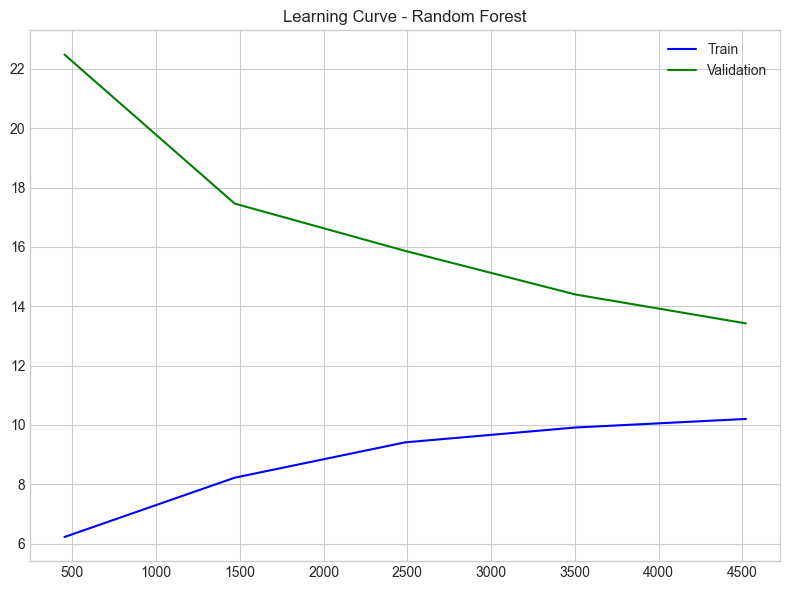

In [132]:
rf_lc

### 10.1.2 - XGB

In [133]:
xgb_lc = plot_learning_curve(best_xgb, X_train, y_train, 'XGB')

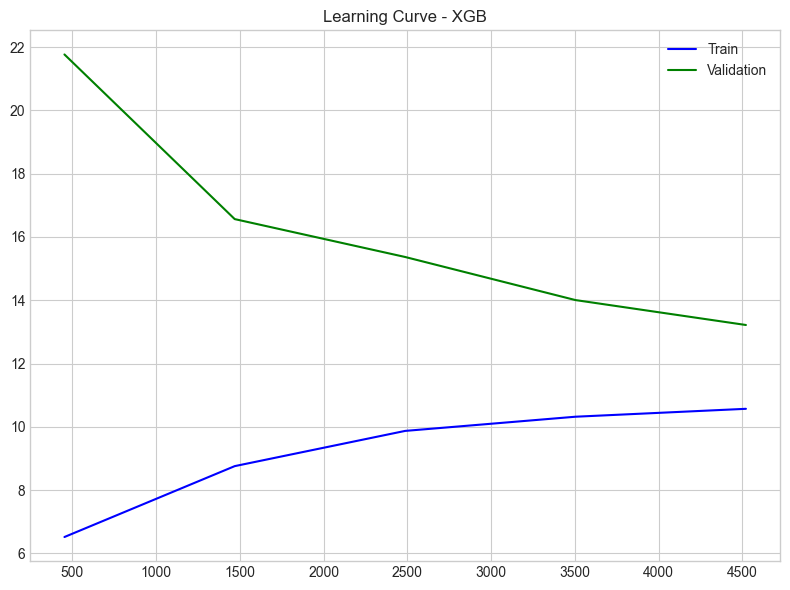

In [134]:
xgb_lc

### 10.1.3 - Extra Trees

In [135]:
et_lc = plot_learning_curve(best_et, X_train, y_train, 'Extra Trees')

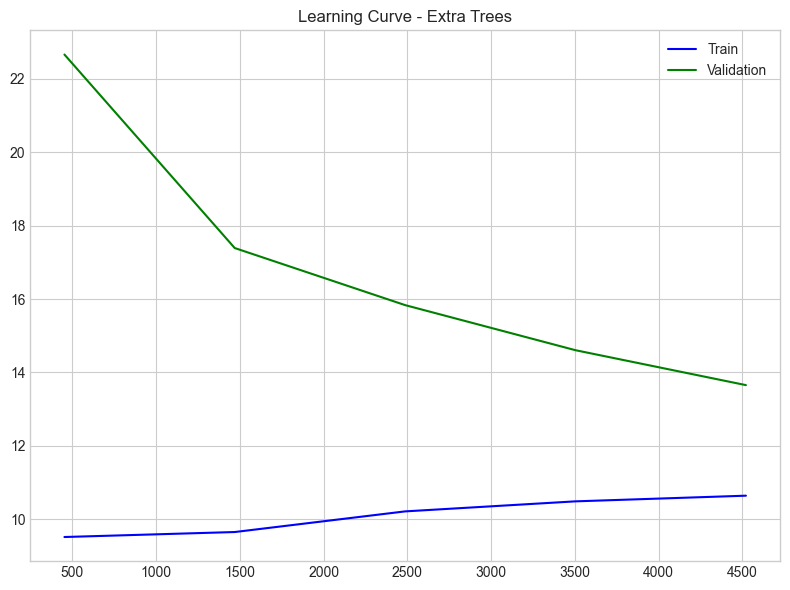

In [136]:
et_lc

### 10.1.4 - Decision Tree

In [137]:
dt_lc = plot_learning_curve(best_dt, X_train, y_train, 'Decision Tree')

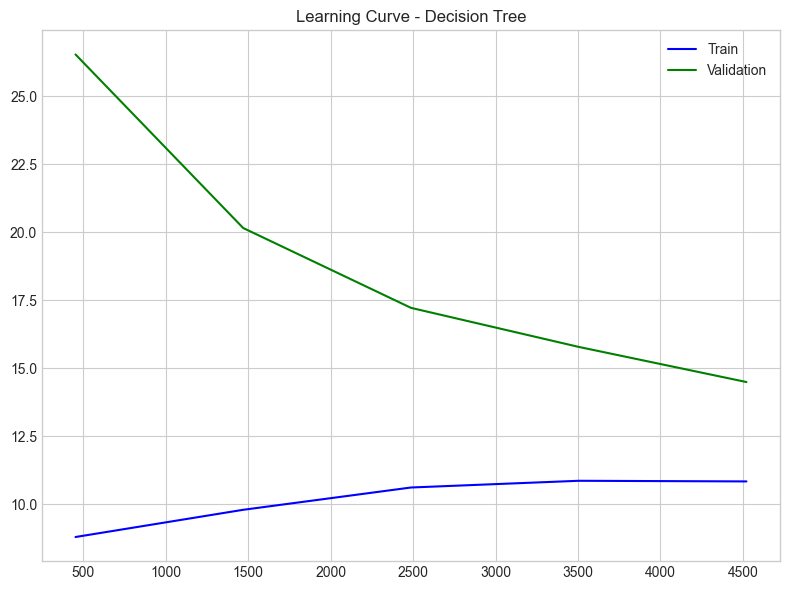

In [138]:
dt_lc

### 10.1.5 - Learning Curve Gap

In [139]:
def plot_learning_curve_gap(models, X, y):

    fig, ax = plt.subplots()

    for name, model in models.items():
        
        train_sizes, train_scores, validation_scores = learning_curve(
            model,
            X,
            y,
            cv=n_cv,
            scoring='neg_root_mean_squared_error',
            n_jobs=-1
        )

        train_scores = -train_scores.mean(axis=1)
        validation_scores = -validation_scores.mean(axis=1)
        gap = validation_scores - train_scores 
        std = np.std(gap)

        diff = gap + std ** 2
        
        ax.plot(train_sizes, diff, label=f'{name}: {np.mean(diff):.3f}', lw=2.3)

    ax.legend()
    plt.tight_layout()
    plt.close()
    return fig

In [140]:
models = {
    'Random Forest': best_rf,
    'XGB': best_xgb,
    'Extra Trees': best_et,
    'Decision Tree': best_dt
}

In [141]:
lcg = plot_learning_curve_gap(models, X_train, y_train)

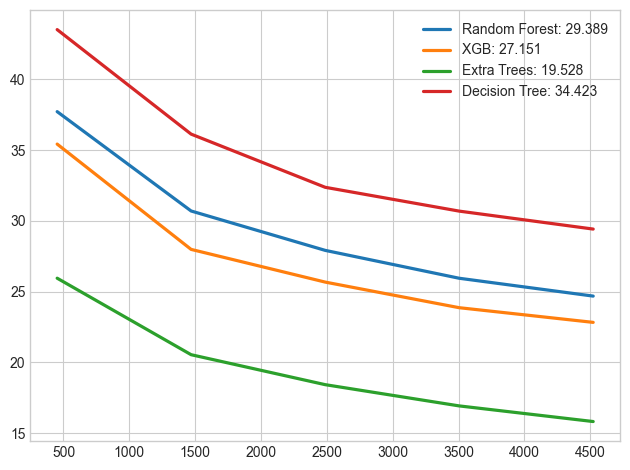

In [142]:
lcg

## 10.2 - Residual Analysis

In [384]:
def plot_residual(*, model, X, y, model_name):
    y_pred = model.predict(X)
    error = y - y_pred

    rmse = np.sqrt(np.mean(error**2))
    mae = np.mean(np.abs(error))
    residual_range = (np.min(error), np.max(error))
    mean_res = np.mean(error)
    
    text_str = (
        f"MAE: {mae:.2f}\n"
        f"RMSE: {rmse:.2f}\n"
        f"Mean Residual: {mean_res:.2f}\n"
        f"Range: [{residual_range[0]:.1f}, {residual_range[1]:.1f}]"
    )
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(y_pred, error, c='steelblue')
    ax.axhline(0, c='red', lw=2)
    ax.set_title(f'Residual Plot - {model_name}', font='serif', fontsize=20, pad=10)
    ax.set_xlabel('$y$ $pred$', font='serif', fontsize=14)
    ax.set_ylabel('Residual ($y$ - $\hat{y}$)', font='serif', fontsize=14)

    plt.text(
        0.02,
        0.98, 
        text_str, 
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top', 
        bbox=dict(
            boxstyle='round', 
            facecolor='white', 
            alpha=0.8
        )
    )
    plt.tight_layout()
    plt.close()
    return fig

<>:22: SyntaxWarning: invalid escape sequence '\h'
<>:22: SyntaxWarning: invalid escape sequence '\h'
C:\Users\alikh\AppData\Local\Temp\ipykernel_20132\3004693360.py:22: SyntaxWarning: invalid escape sequence '\h'
  ax.set_ylabel('Residual ($y$ - $\hat{y}$)', font='serif', fontsize=14)


### 10.2.1 - Random Forest

In [385]:
rf_res = plot_residual(
    model=best_rf,
    X=X_train, 
    y=y_train,
    model_name='Rnadom Forest'
)

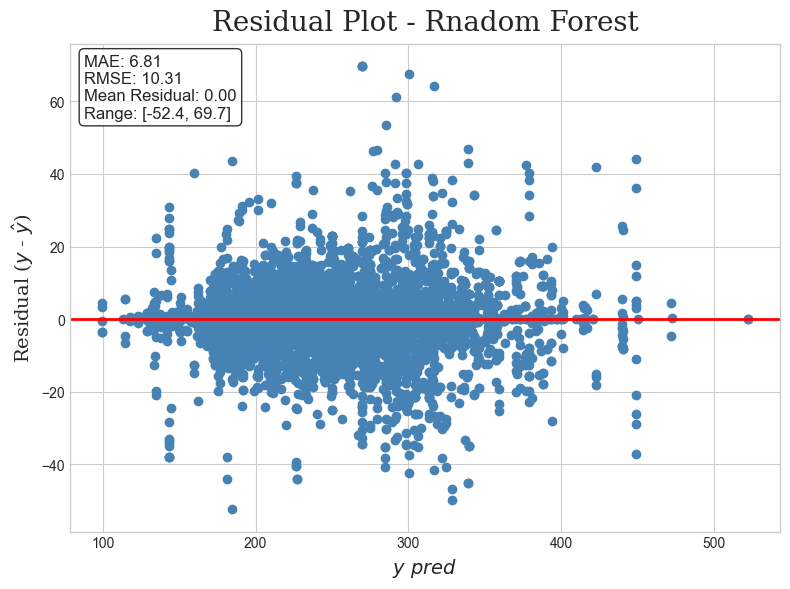

In [386]:
rf_res

### 10.2.2 - XGB

In [387]:
xgb_res = plot_residual(
    model=best_xgb,
    X=X_train,
    y=y_train,
    model_name='XGB'
)

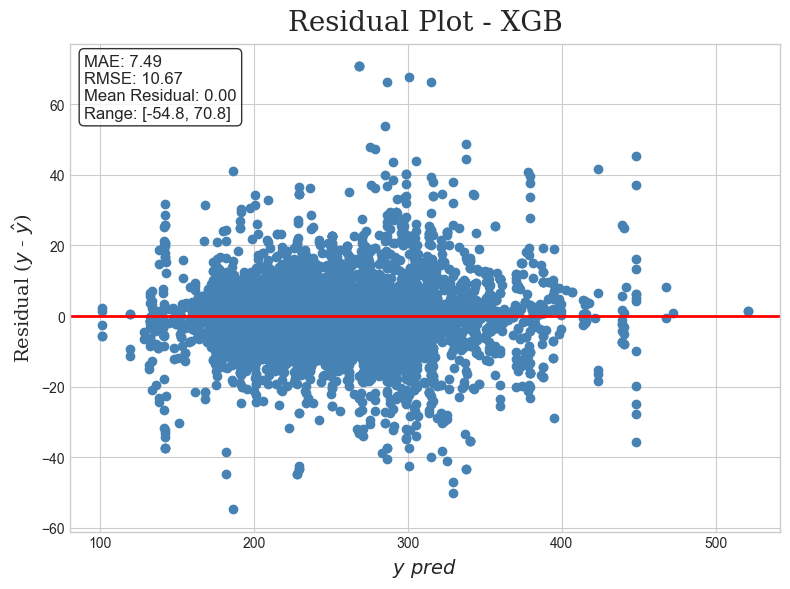

In [388]:
xgb_res

### 10.2.3 - Extra Trees

In [389]:
et_res = plot_residual(
    model=best_et,
    X=X_train,
    y=y_train,
    model_name='Extra Trees'
)

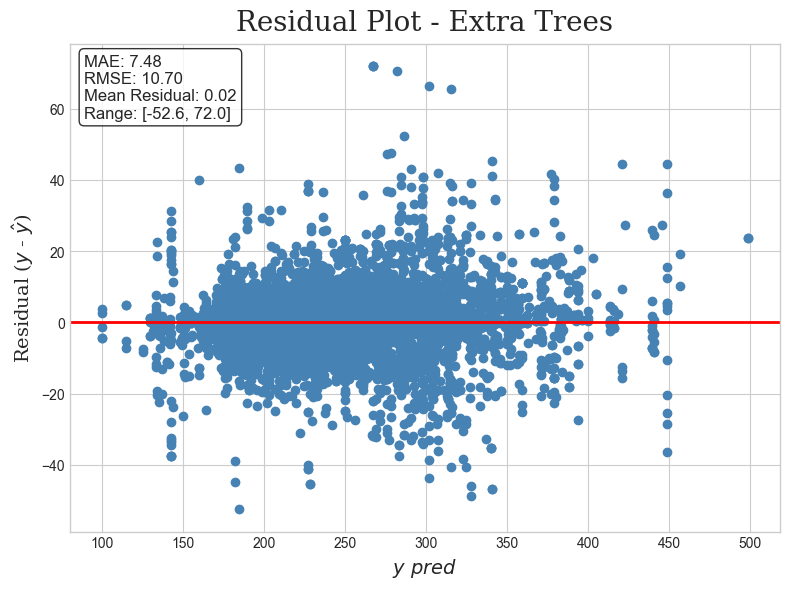

In [390]:
et_res

### 10.2.4 - Decision Tree

In [391]:
dt_res = plot_residual(
    model=best_dt,
    X=X_train,
    y=y_train,
    model_name='Decision Tree'
)

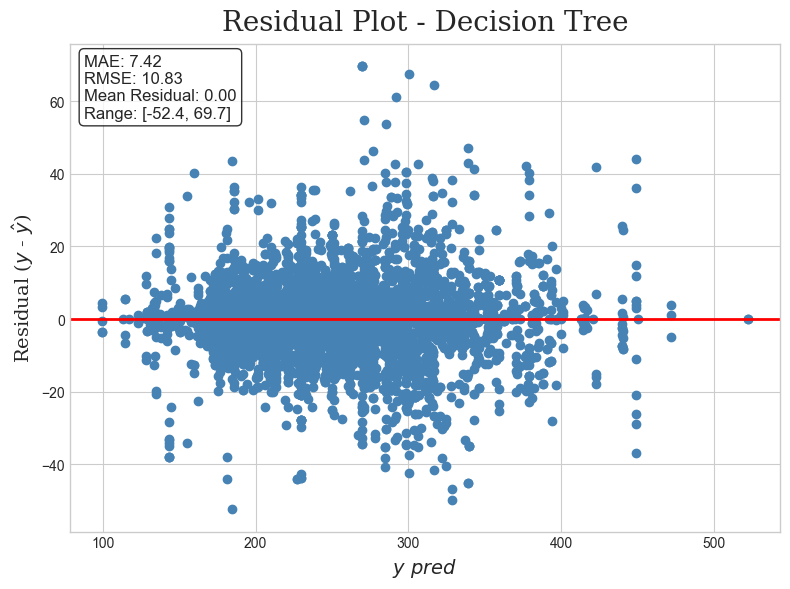

In [392]:
dt_res

## 10.3 - Parity Plot

In [351]:
def plot_praity(*, model, X, y, model_name):
    y_pred = model.predict(X)
    min_val = min(y.min(), y_pred.min())
    max_val = max(y.max(), y_pred.max())

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(y, y_pred, c='steelblue', alpha=0.4)
    ax.plot([min_val, max_val], [min_val, max_val], c='red', lw=2)
    ax.set_xlabel('$y$', font='serif', fontsize=15)
    ax.set_ylabel('$\hat{y}$', font='serif', fontsize=15)
    ax.set_title(f'Parity Plot - {model_name}', font='serif', fontsize=20, pad=10)
    plt.tight_layout()
    plt.close()
    return fig

<>:10: SyntaxWarning: invalid escape sequence '\h'
<>:10: SyntaxWarning: invalid escape sequence '\h'
C:\Users\alikh\AppData\Local\Temp\ipykernel_20132\203315607.py:10: SyntaxWarning: invalid escape sequence '\h'
  ax.set_ylabel('$\hat{y}$', font='serif', fontsize=15)


### 10.3.1 - Random Forest

In [352]:
rf_parity = plot_praity(
    model=best_rf,
    X=X_train,
    y=y_train,
    model_name='Random Forest'
)

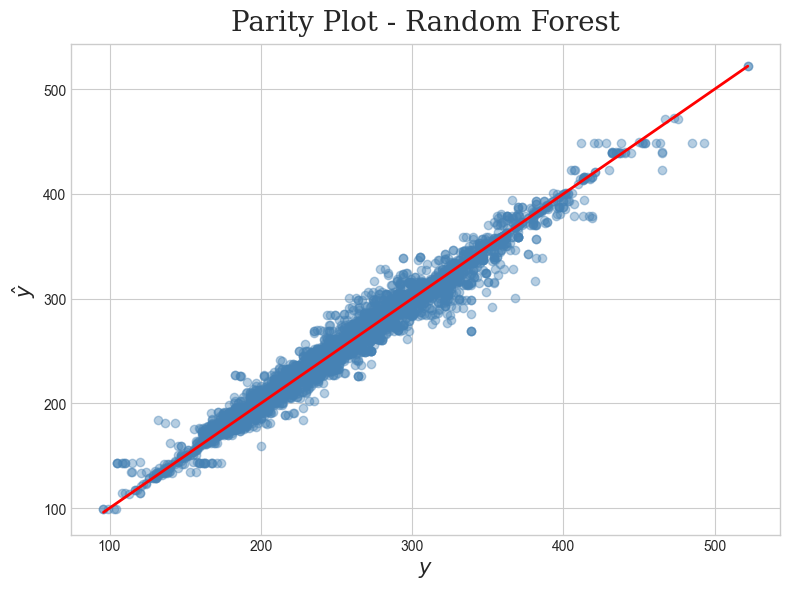

In [345]:
rf_parity

### 10.3.2 - XGB

In [353]:
xgb_parity = plot_praity(
    model=best_xgb,
    X=X_train,
    y=y_train,
    model_name='XGB'
)

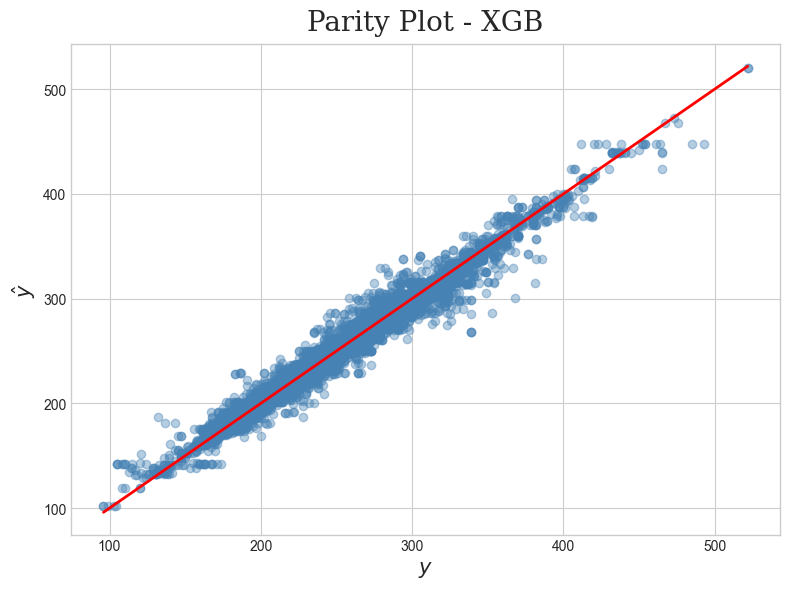

In [347]:
xgb_parity

### 10.3.3 - Extra Trees

In [354]:
et_parity = plot_praity(
    model=best_et,
    X=X_train,
    y=y_train,
    model_name='Extra Trees'
)

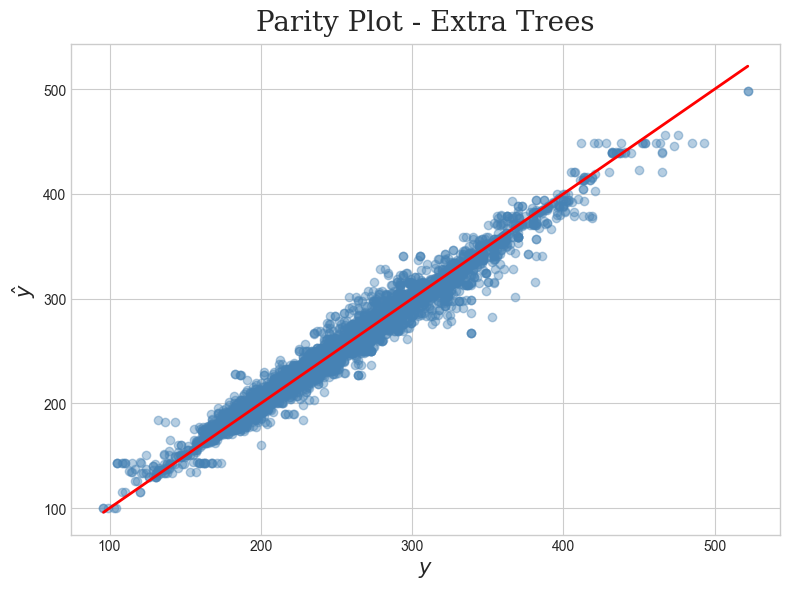

In [349]:
et_parity

### 10.3.4 - Decision Tree

In [355]:
dt_parity = plot_praity(
    model=best_dt,
    X=X_train,
    y=y_train,
    model_name='Decision Tree'
)

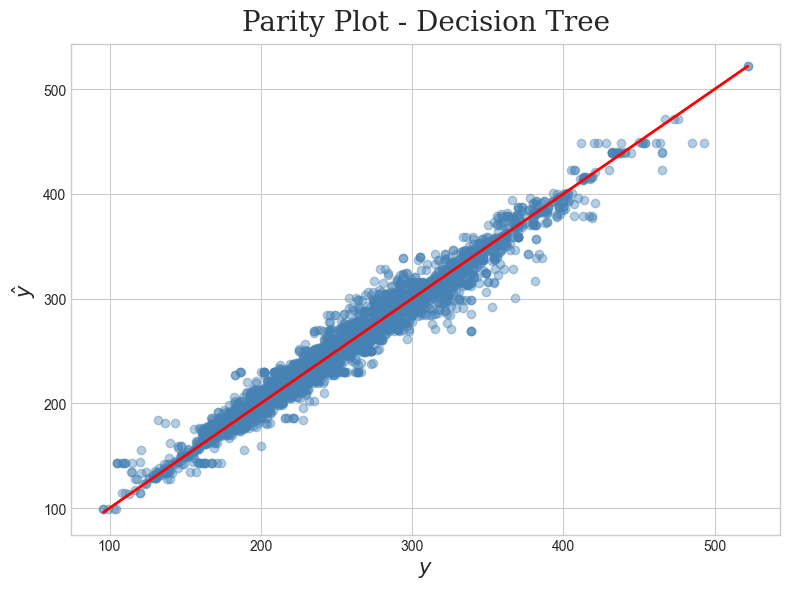

In [160]:
dt_parity

## 10.4 - Feature Importance

In [161]:
def plot_feature_importance(*, model, feature_names, model_name):
    estimator = model.named_steps['model']
    

    importances = estimator.feature_importances_

    importance = pd.Series(importances, index=feature_names).sort_values()


    fig, ax = plt.subplots(figsize=(20,20))

    importance.plot.barh(ax=ax)

    ax.set_title(f'Feature Importance - {model_name}', font='serif', fontsize=20, pad=10)
    ax.set_xlabel("Importance", font='serif', fontsize=15)

    plt.tight_layout()
    plt.close(fig)
    return fig

In [162]:
feature_names = build_pipeline(
    preprocessor=preprocessor, 
    feature_builder=build_features,
    model=None
).fit_transform(
    X_train, 
    y_train
).columns

### 10.4.1 - Ranodm Forest

In [163]:
rf_feature_imp = plot_feature_importance(
    model=best_rf,
    feature_names=feature_names,
    model_name='Random Forest'
)

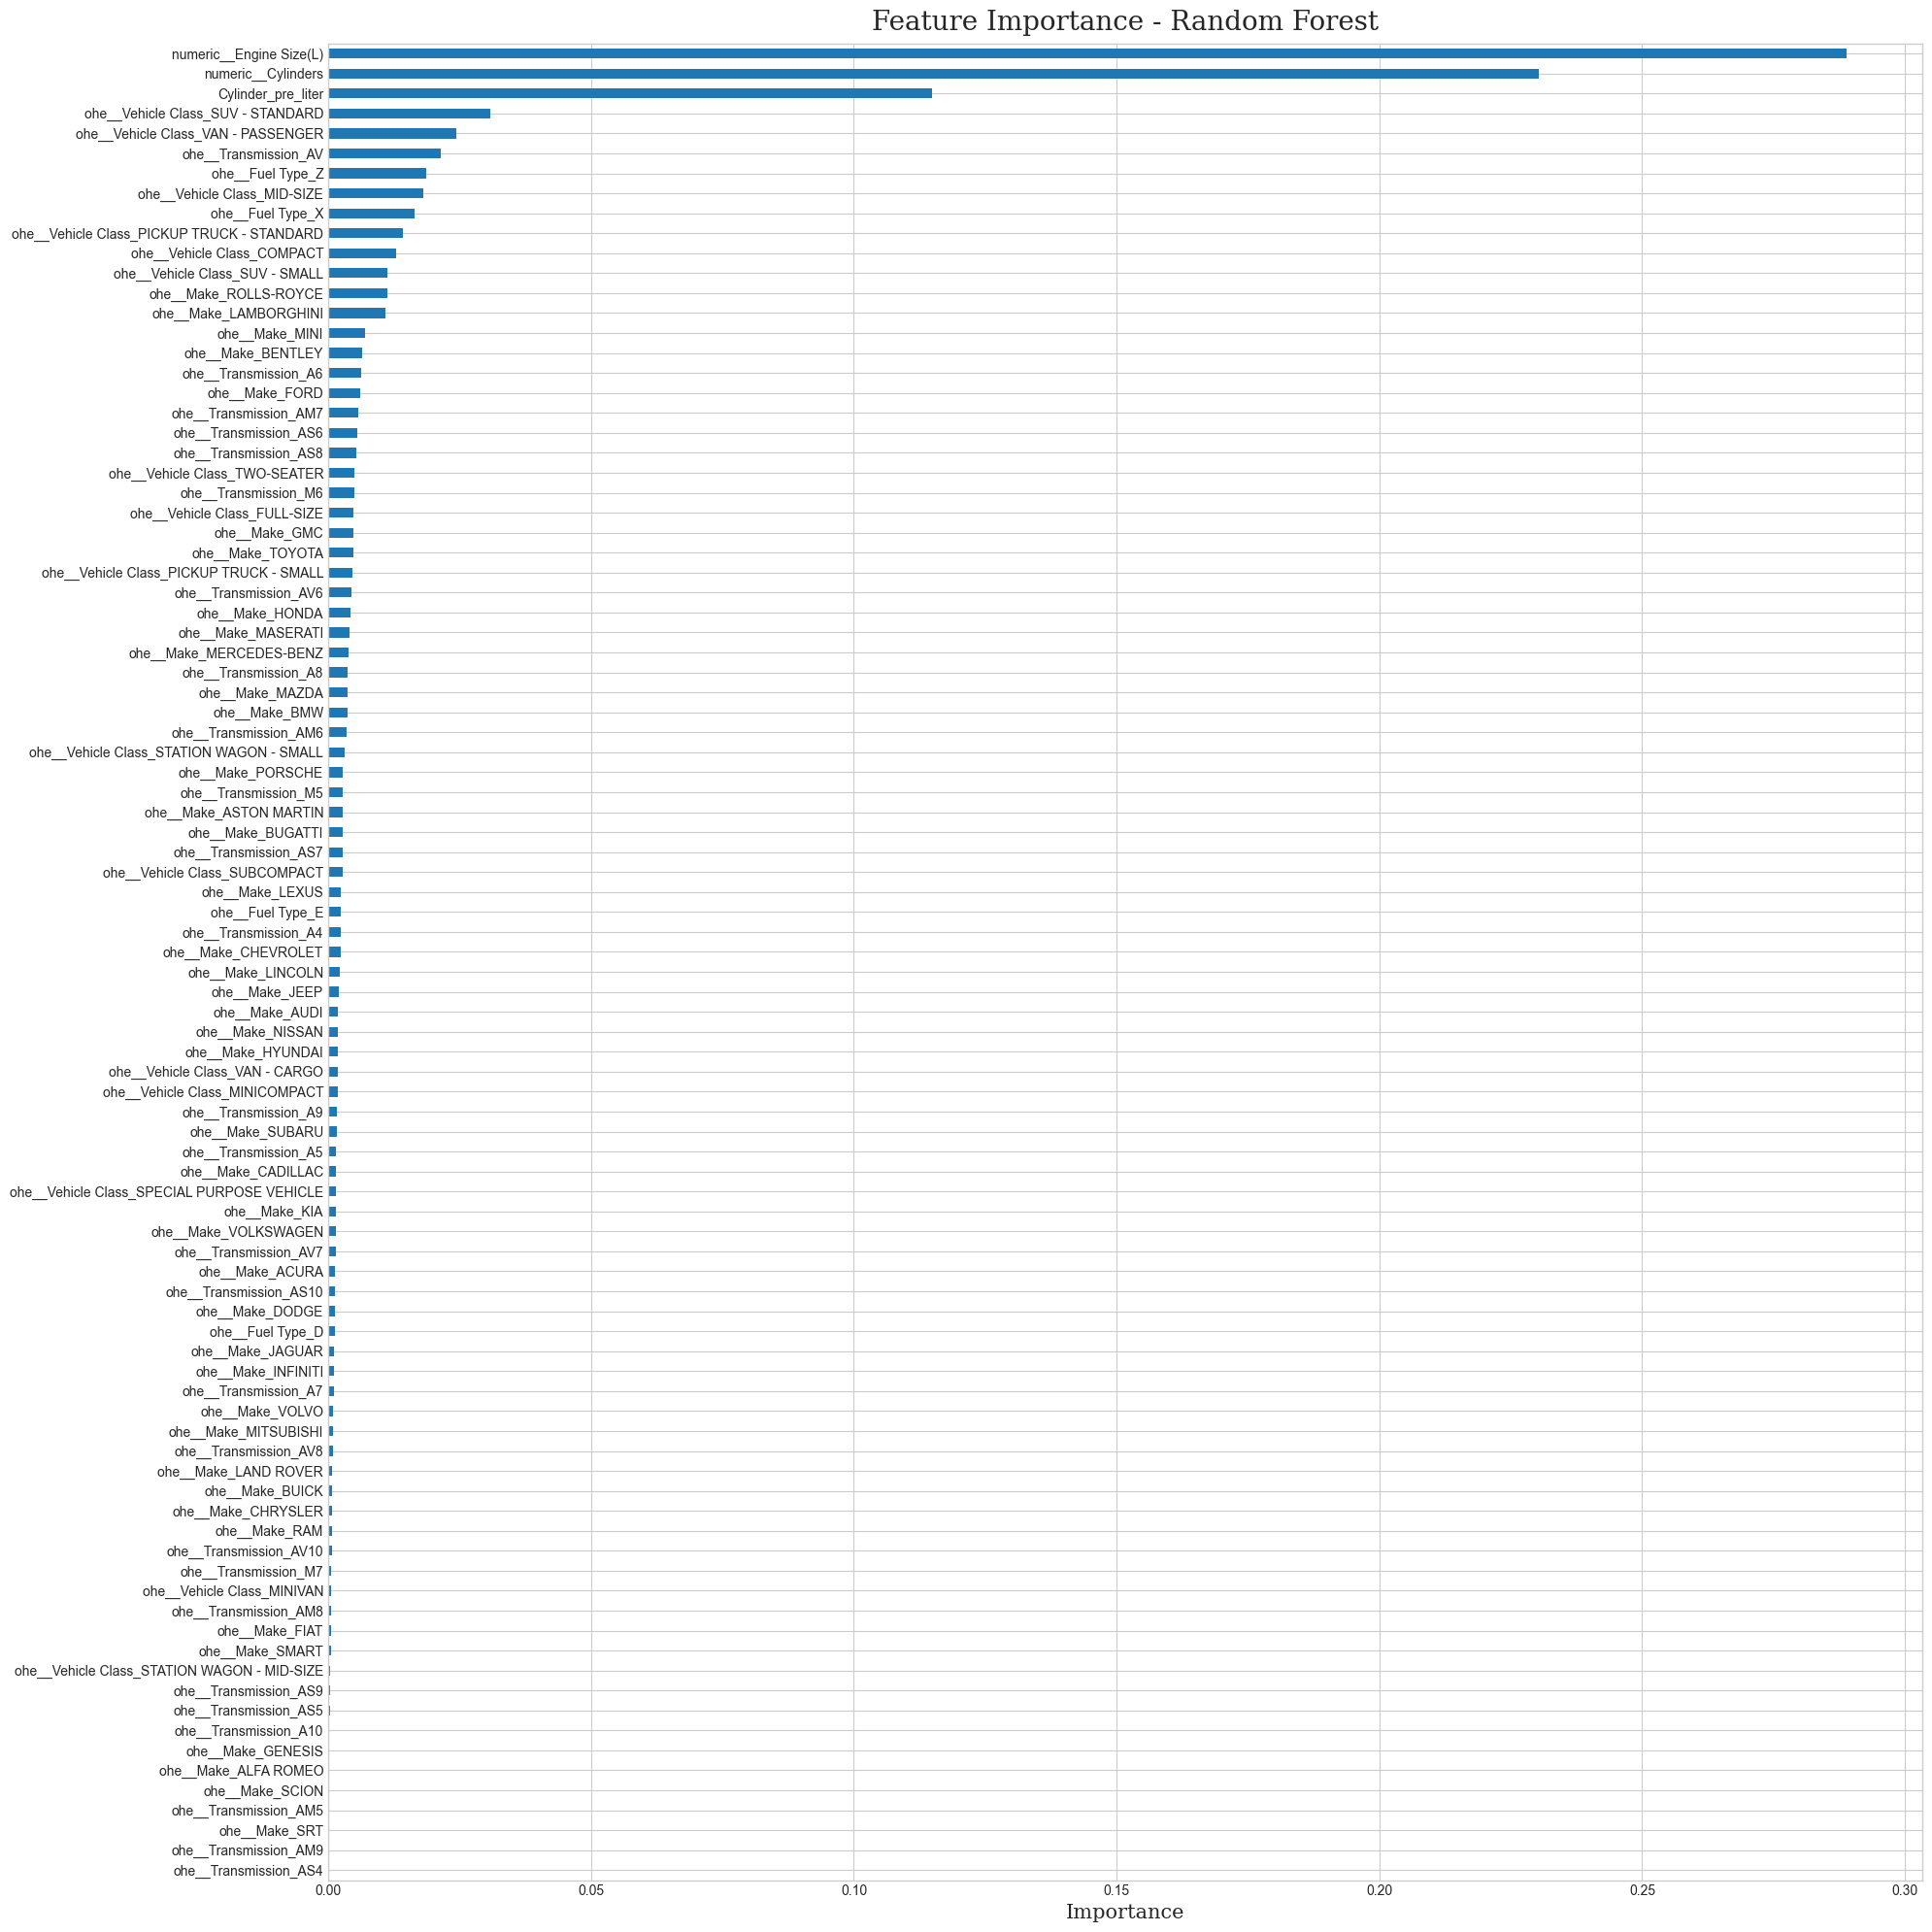

In [164]:
rf_feature_imp

### 10.4.2 - XGB

In [165]:
xgb_feature_imp = plot_feature_importance(
    model=best_xgb,
    feature_names=feature_names,
    model_name='XGB'
)

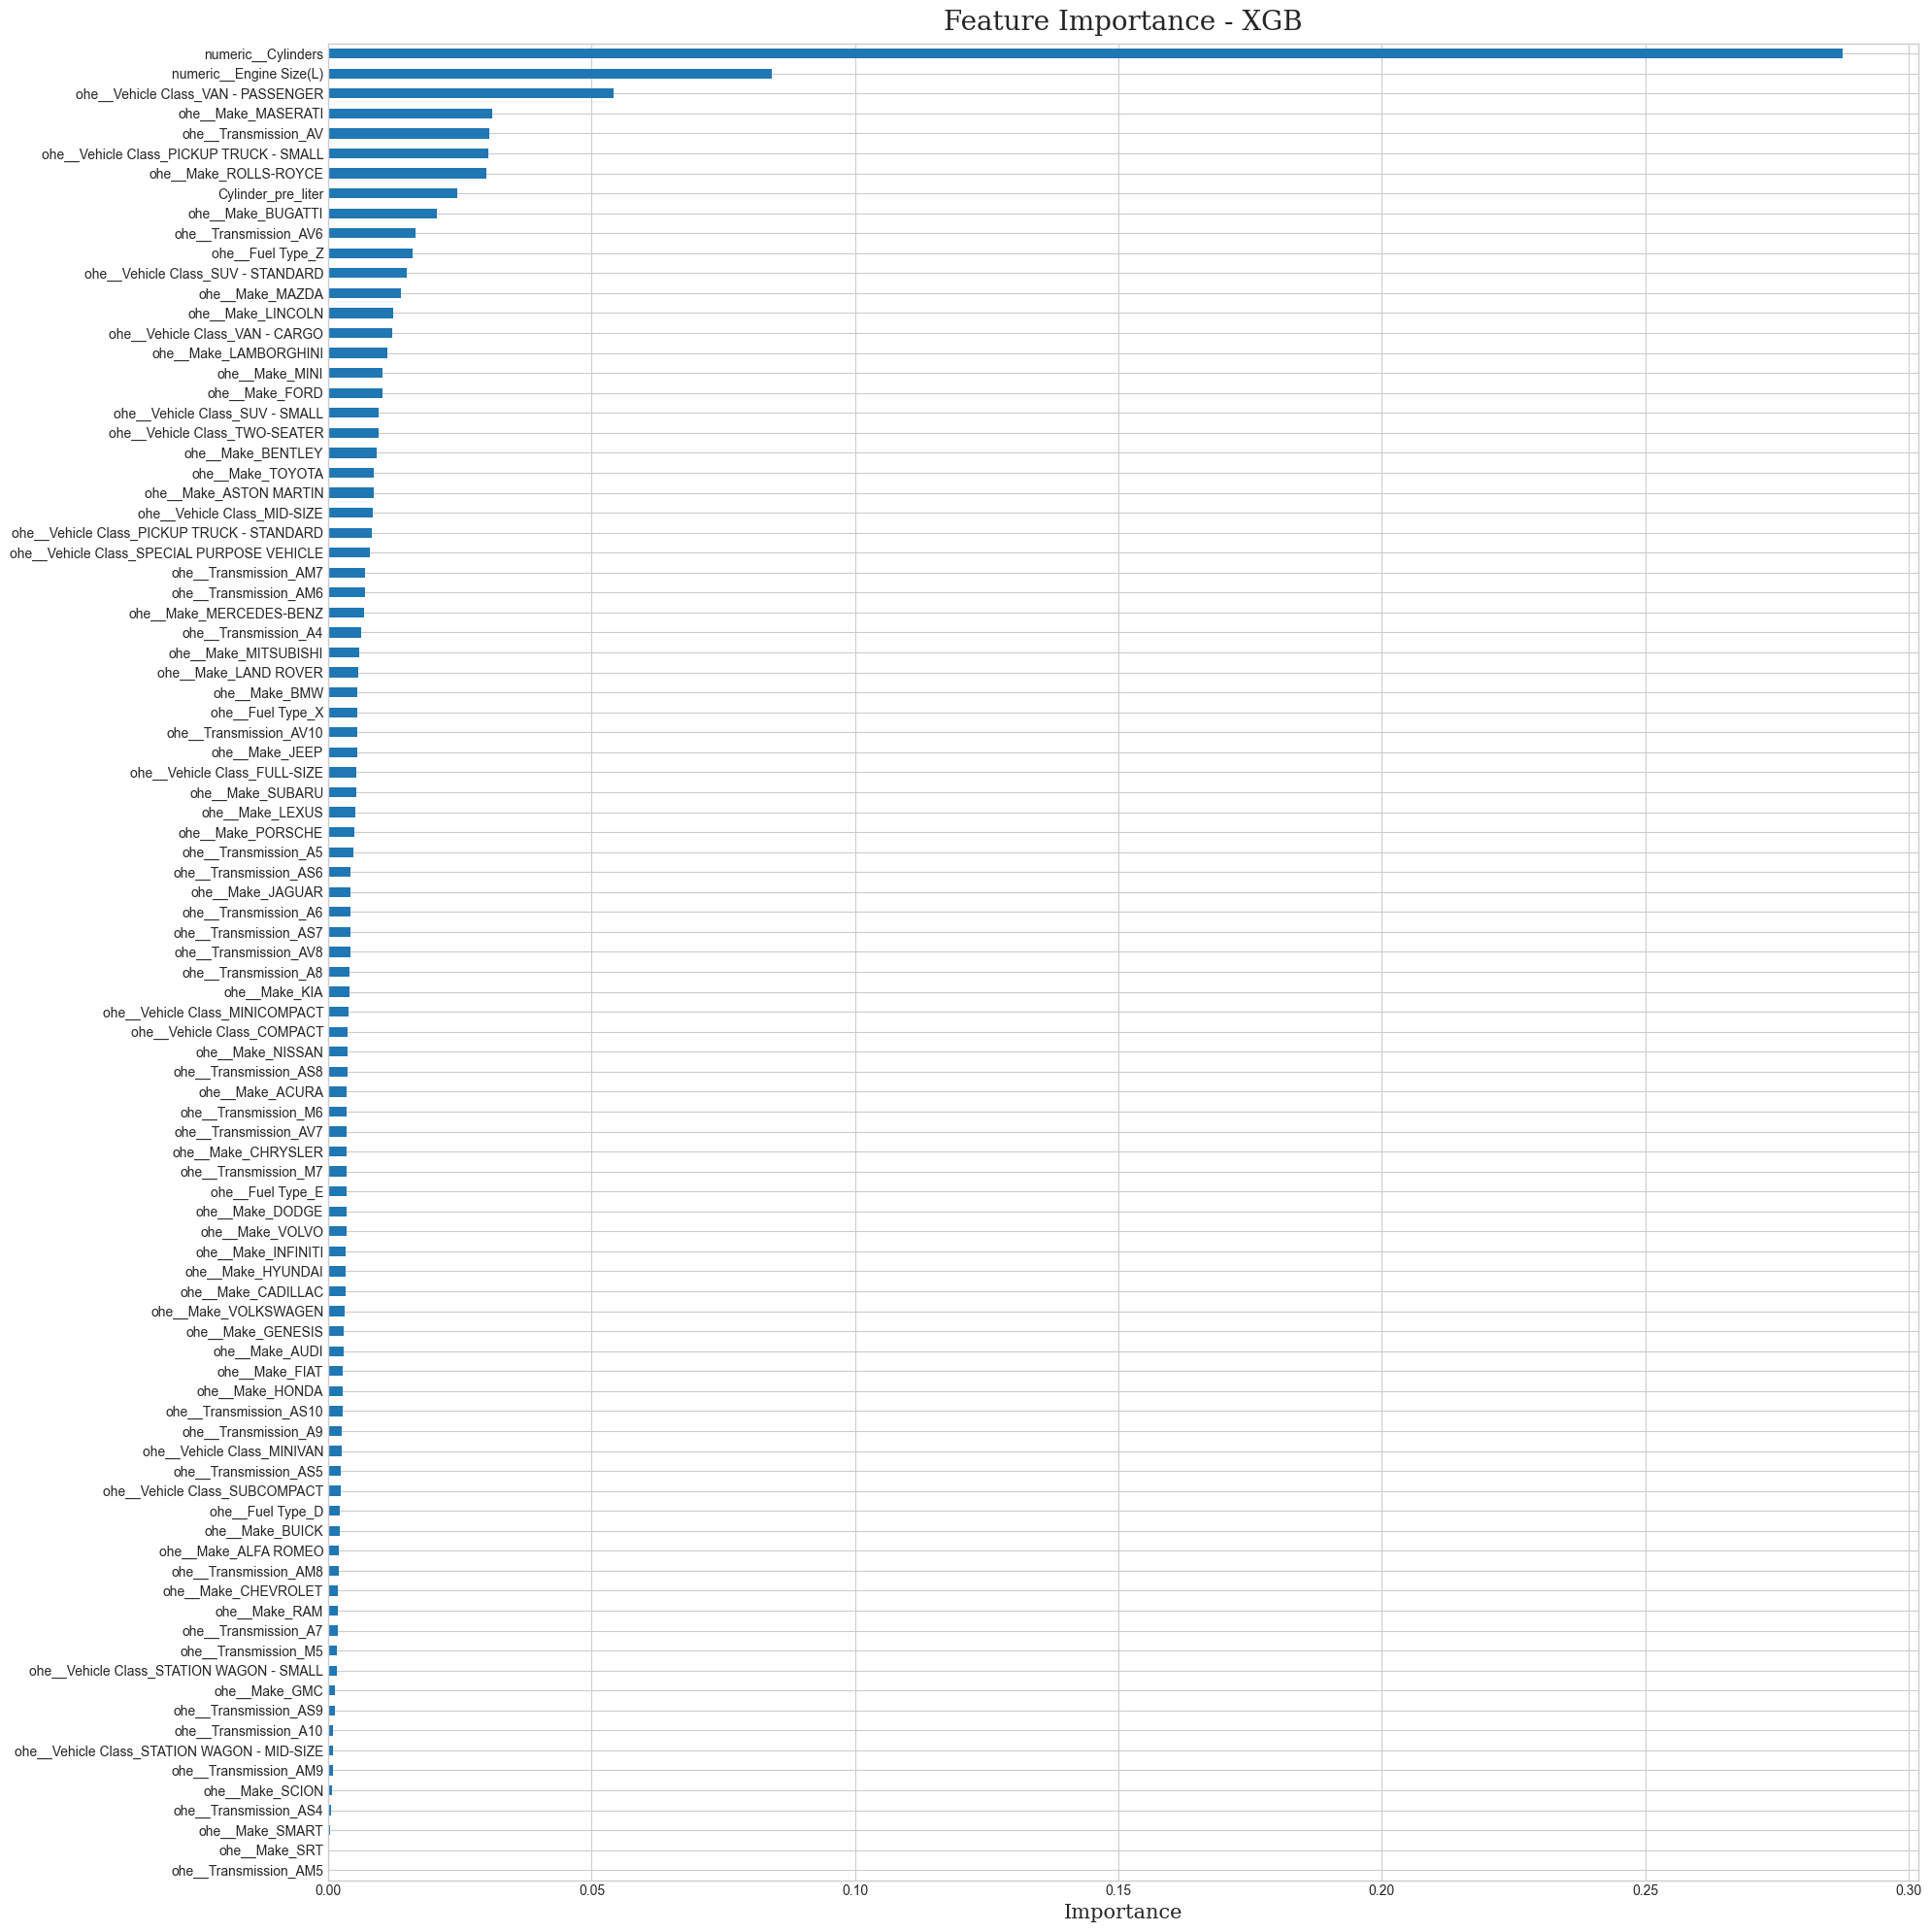

In [166]:
xgb_feature_imp

### 10.4.3 - Extra Trees

In [167]:
et_feature_imp = plot_feature_importance(
    model=best_et,
    feature_names=feature_names,
    model_name='Extra Trees'
)

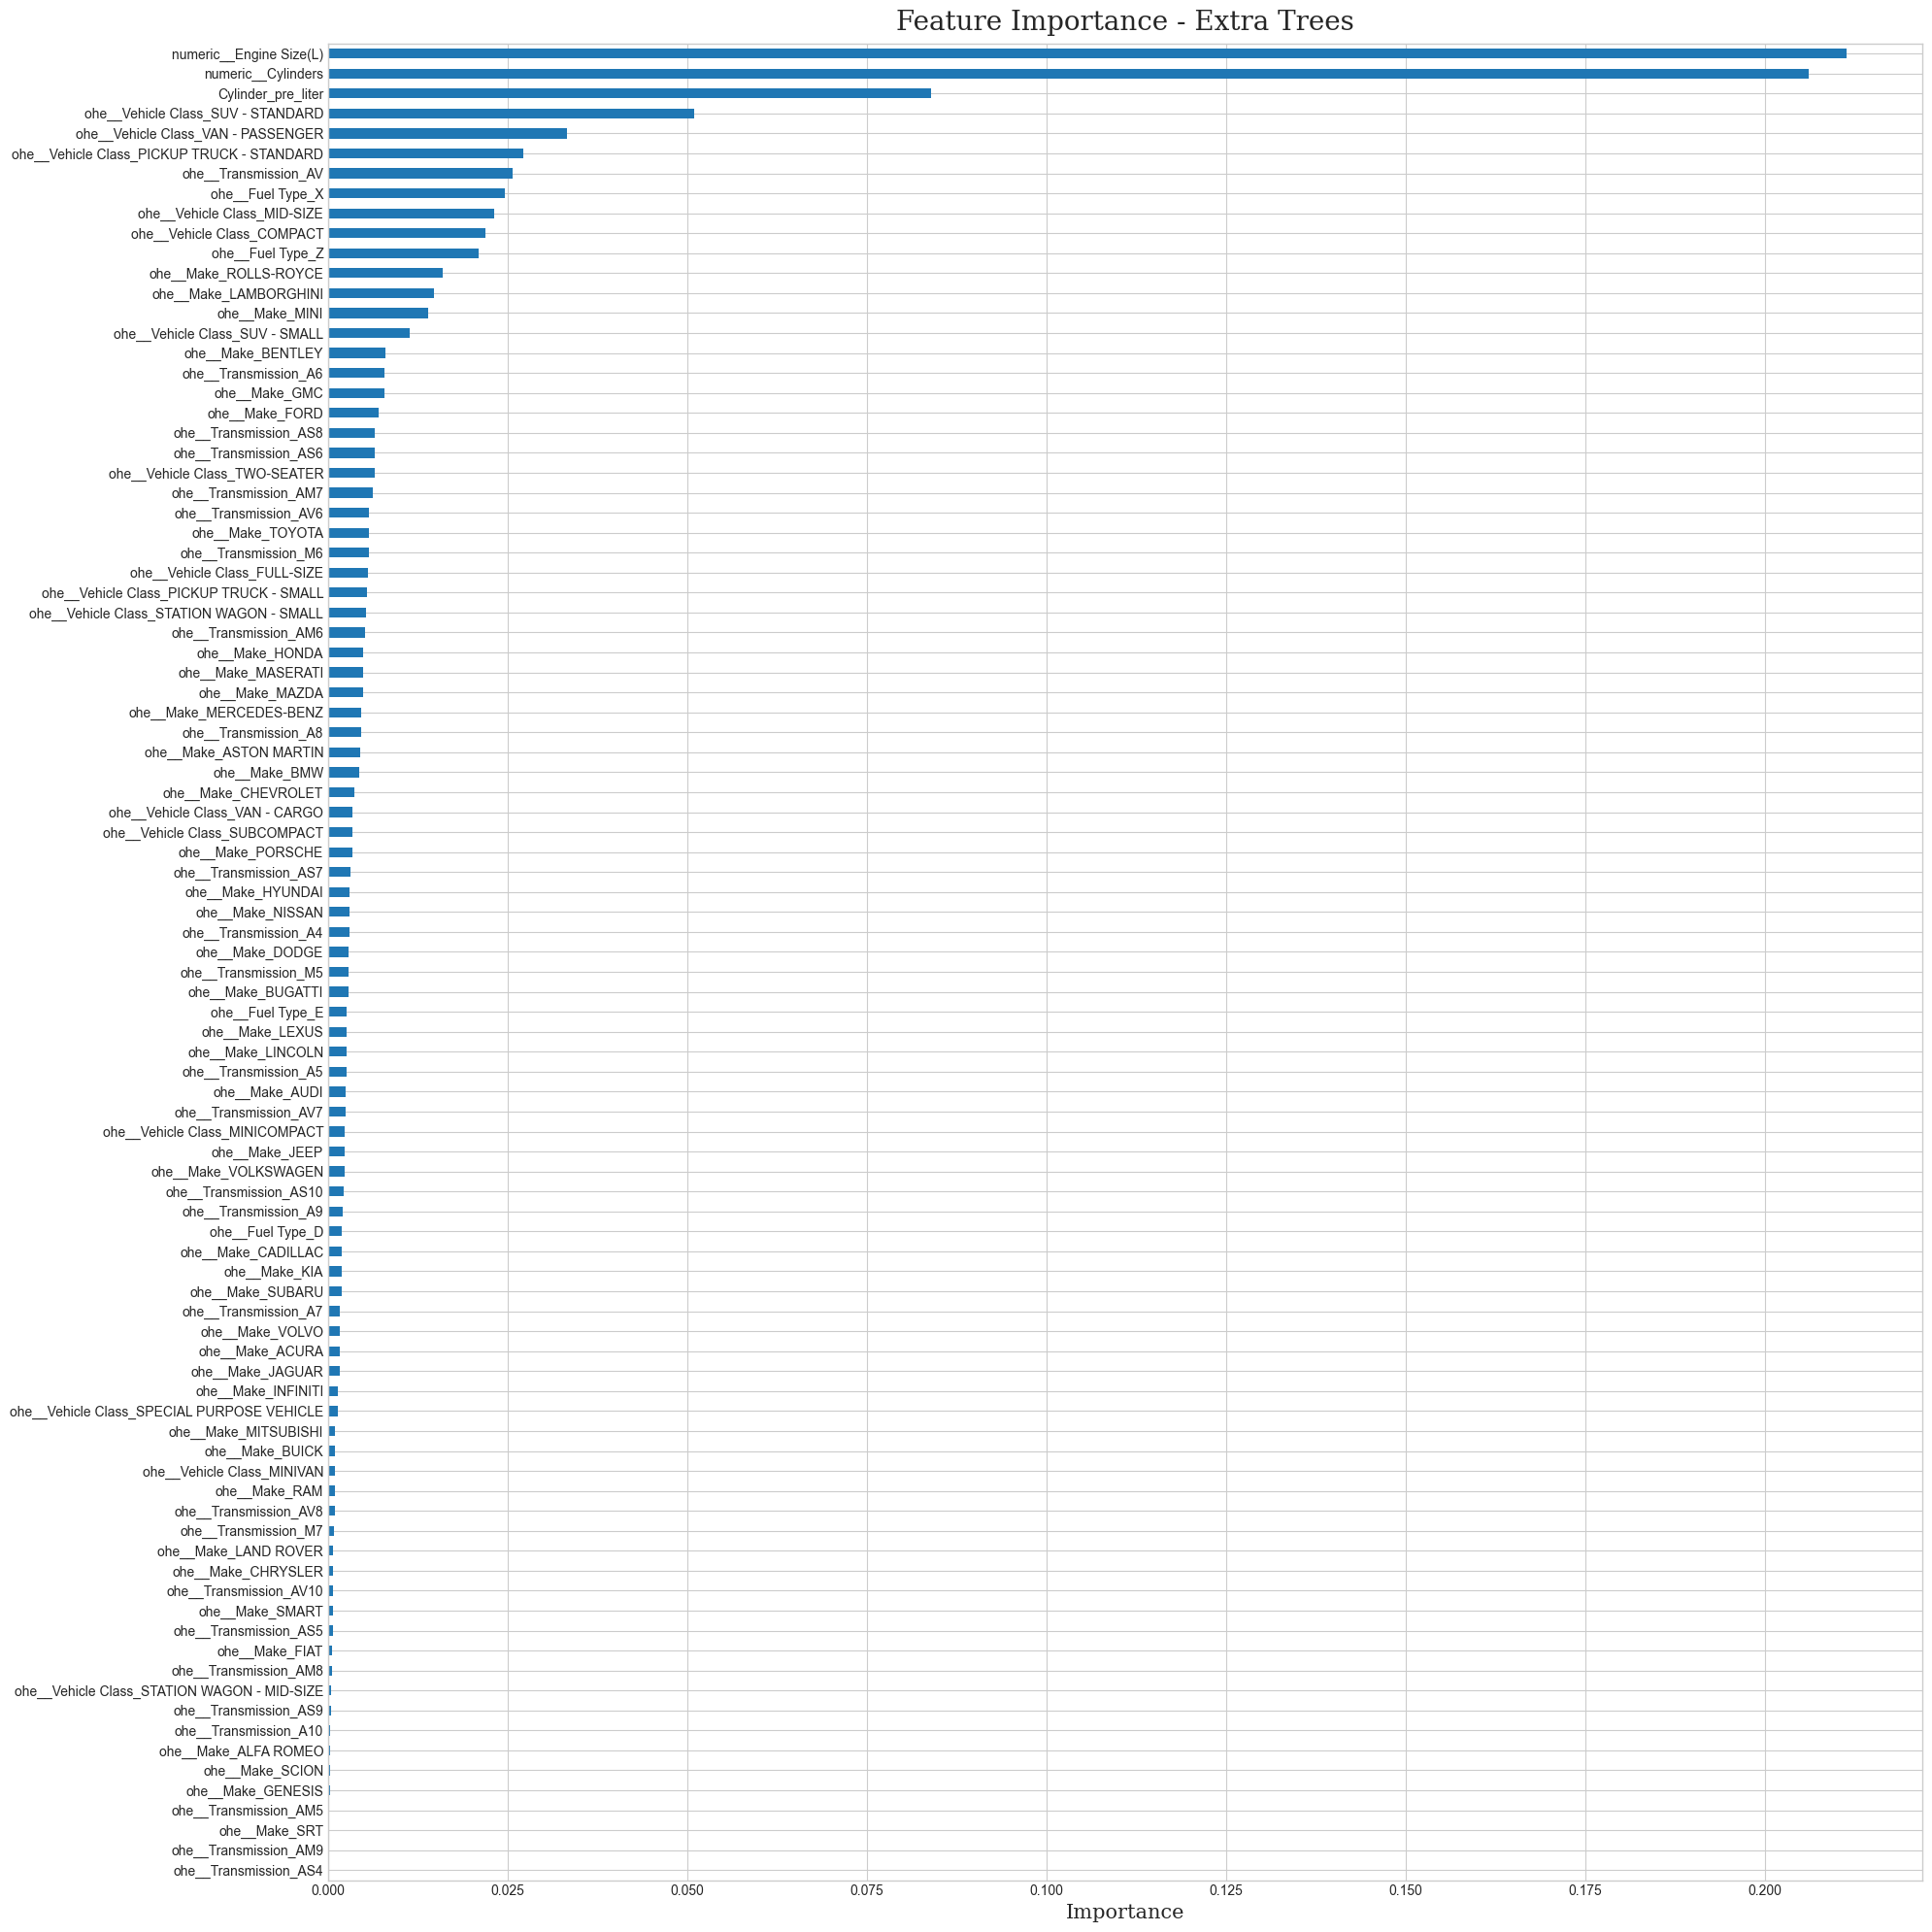

In [168]:
et_feature_imp

### 10.4.4 - Decision Tree

In [169]:
dt_feature_imp = plot_feature_importance(
    model=best_dt,
    feature_names=feature_names,
    model_name='Decision Tree'
)

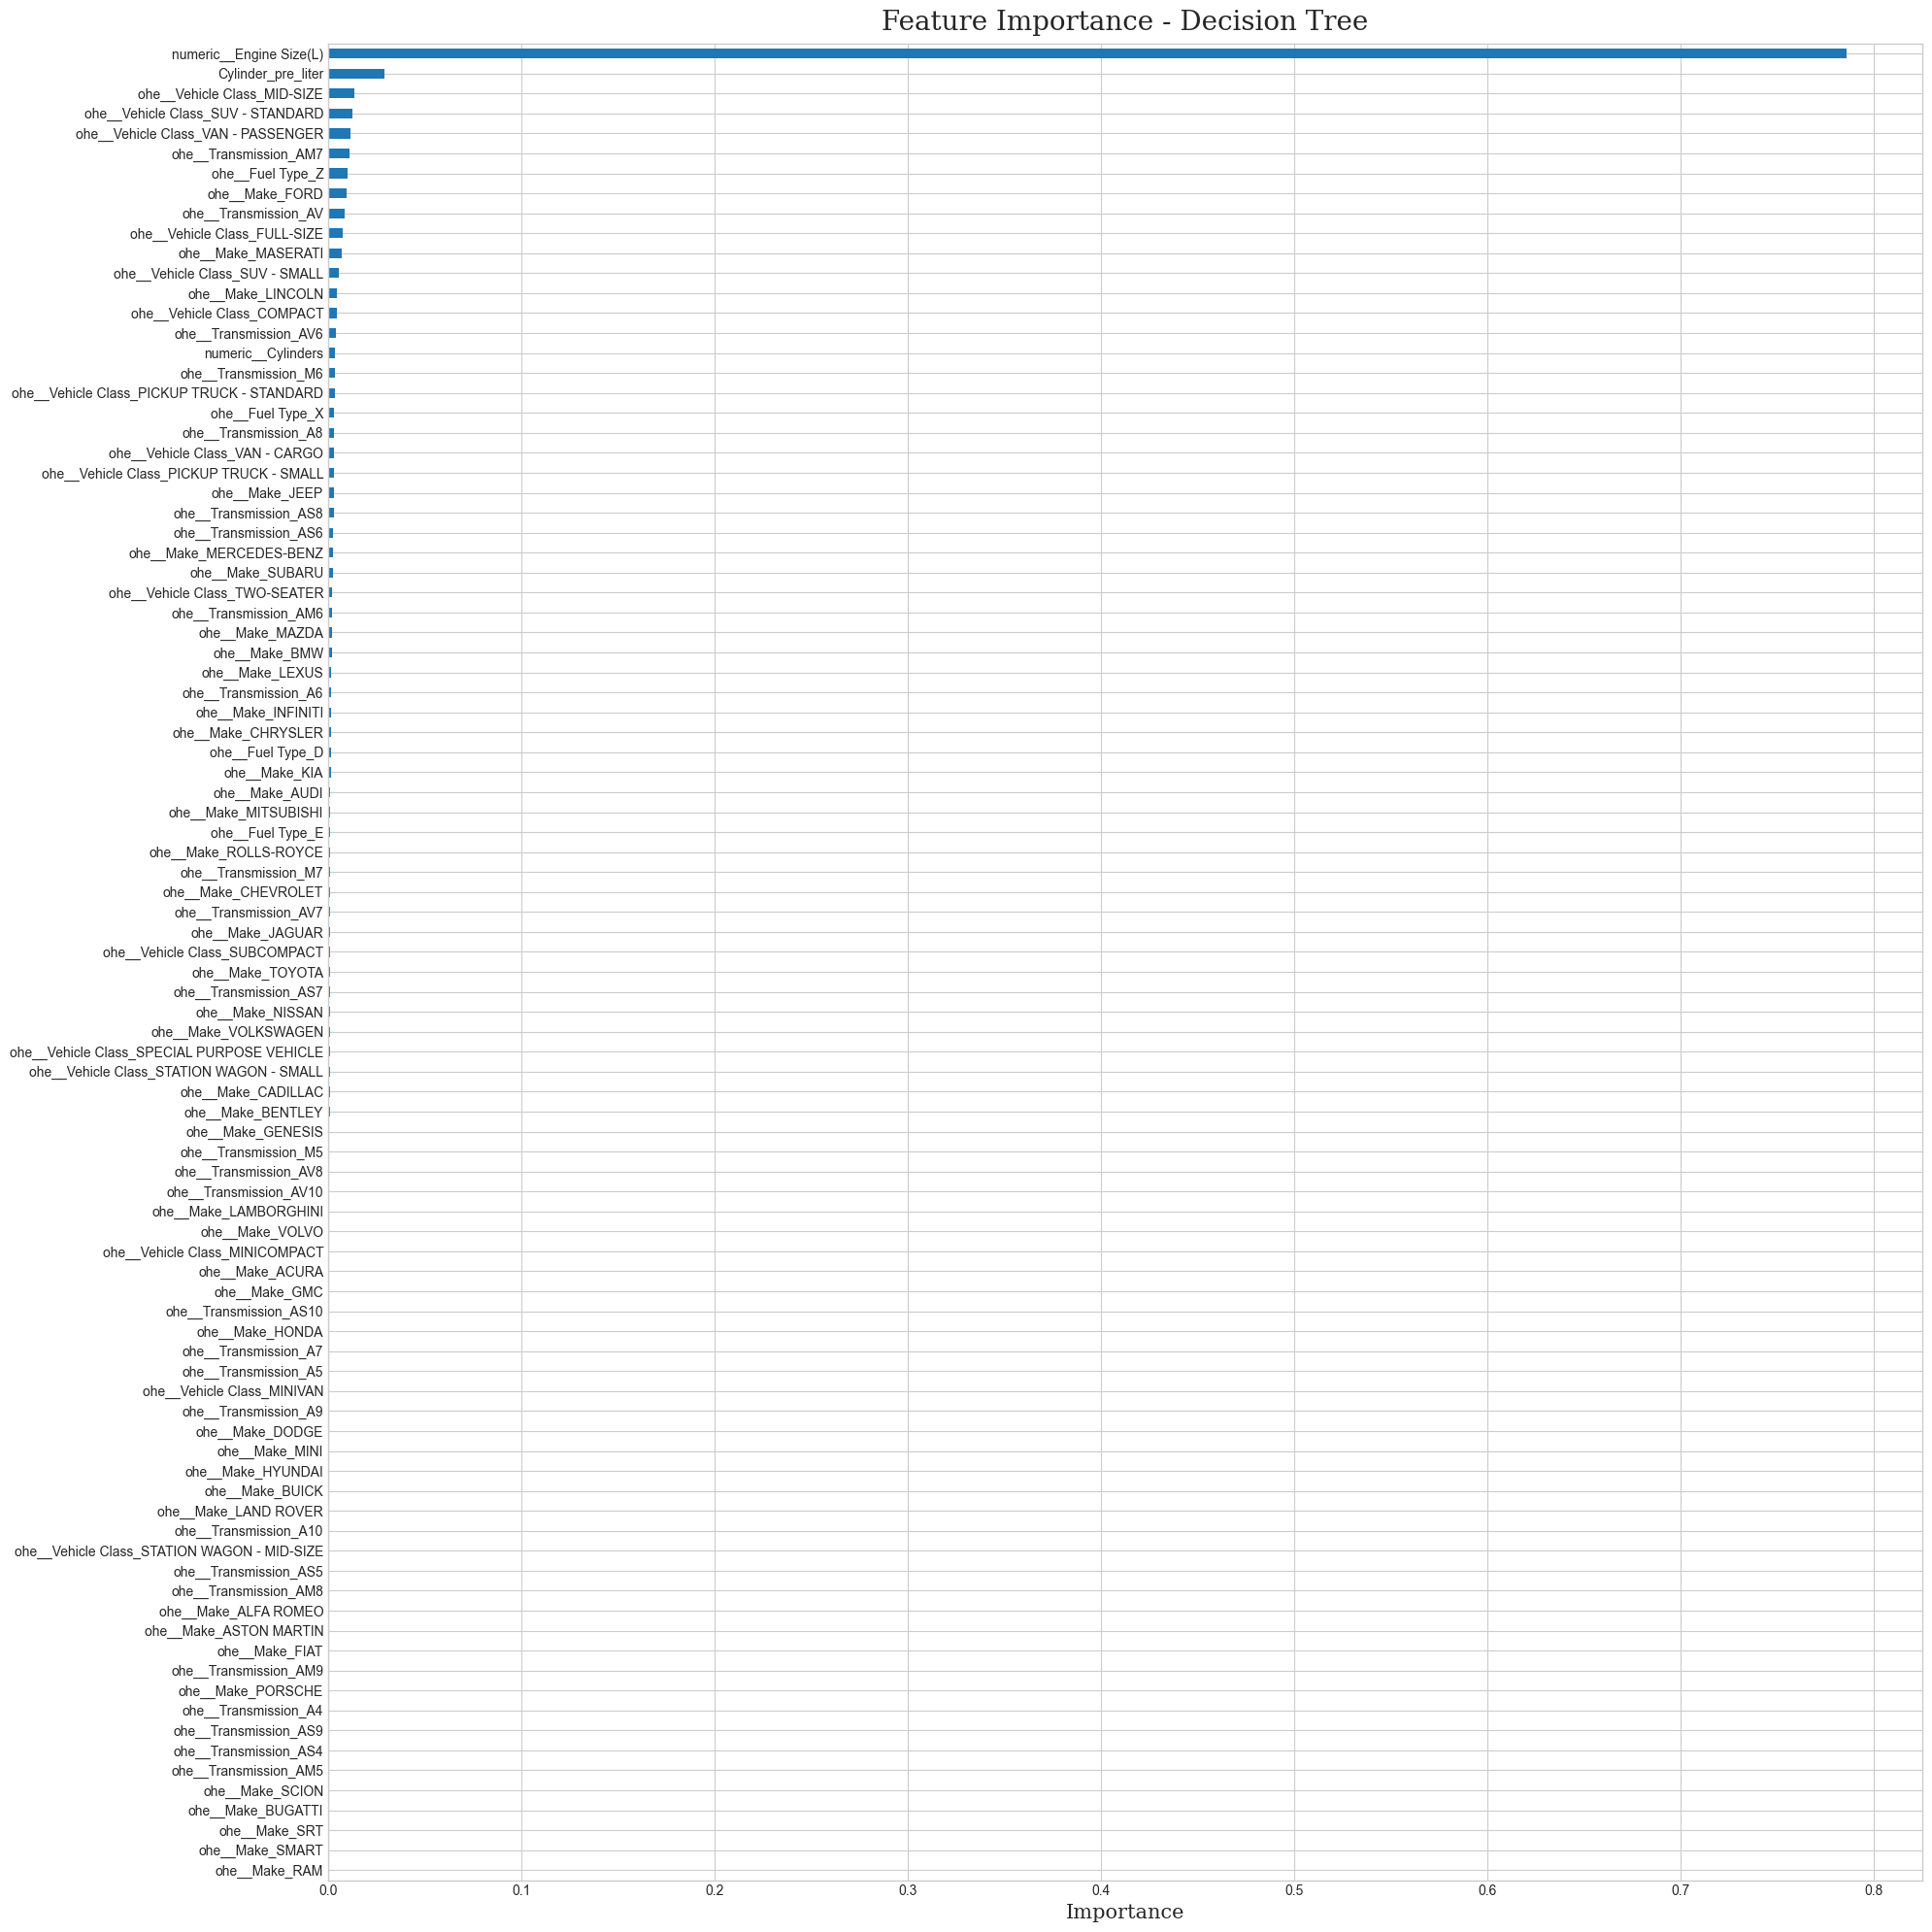

In [170]:
dt_feature_imp

## 10.5 - Permutation Importance

In [171]:
def compute_permutation_importance(*, model, X, y, feature_names):

    perm_importance = permutation_importance(
        model,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    perm_importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": perm_importance.importances_mean,
        "Std": perm_importance.importances_std
    })
    
    perm_importance_df = perm_importance_df.sort_values(
        "Importance",
        ascending=False
    )

    return perm_importance_df.set_index('Feature', drop=True)

### 10.5.1 - Random Forest

In [172]:
rf_pi = compute_permutation_importance(
    model=best_rf,
    X=X_train,
    y=y_train,
    feature_names=X_train.columns
)

In [173]:
rf_pi

,Importance,Std
Feature,,
Engine Size(L),39.984856,0.310231
Cylinders,14.851125,0.187250
Vehicle Class,14.841432,0.152023
Transmission,9.073689,0.133098
Make,8.624883,0.203971
Fuel Type,7.505009,0.144566


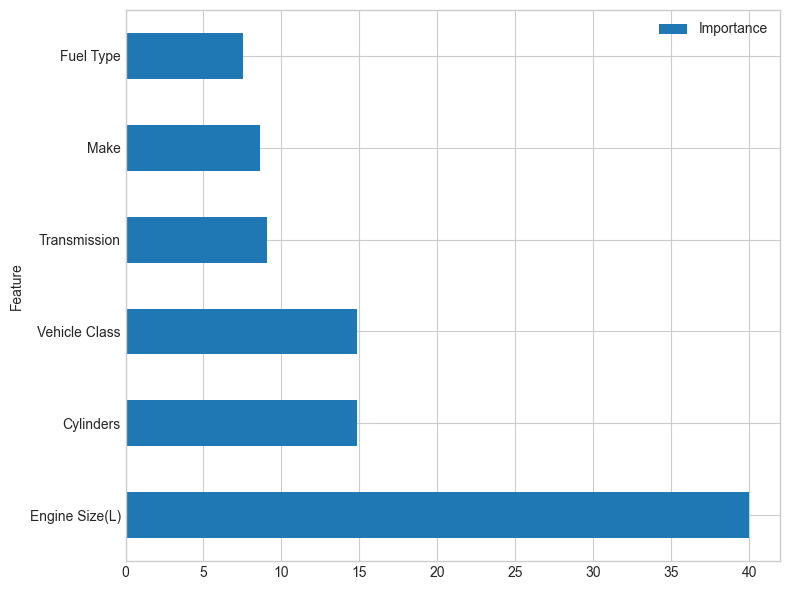

In [366]:
rf_pi.drop('Std', axis=1).plot(kind='barh', figsize=(8, 6))
plt.tight_layout()
plt.show()

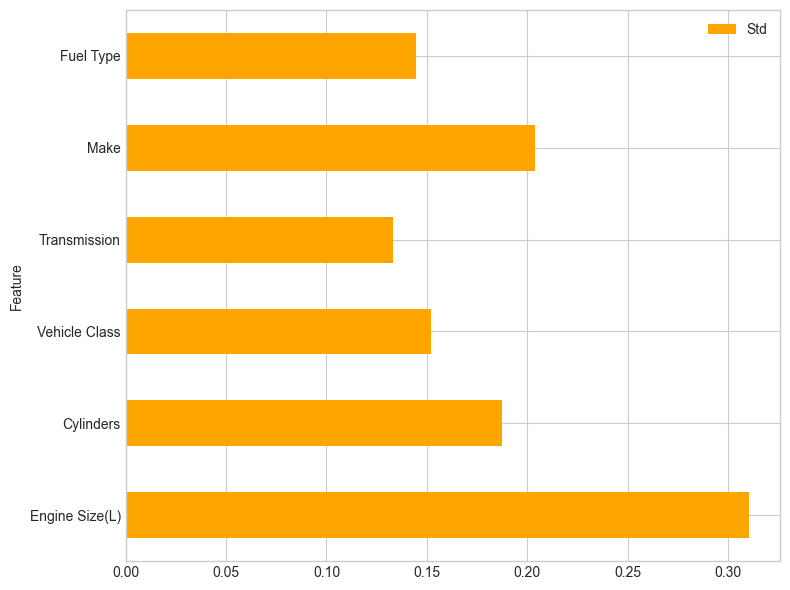

In [367]:
rf_pi.drop('Importance', axis=1).plot(kind='barh', figsize=(8, 6), color='orange')
plt.tight_layout()
plt.show()

### 10.5.2 - XGB

In [176]:
xgb_pi = compute_permutation_importance(
    model=best_xgb,
    X=X_train,
    y=y_train,
    feature_names=X_train.columns
)

In [177]:
xgb_pi

,Importance,Std
Feature,,
Engine Size(L),45.871548,0.312370
Vehicle Class,13.987079,0.141155
Cylinders,12.839278,0.210722
Transmission,8.564549,0.141510
Make,8.298772,0.237349
Fuel Type,5.123823,0.078491


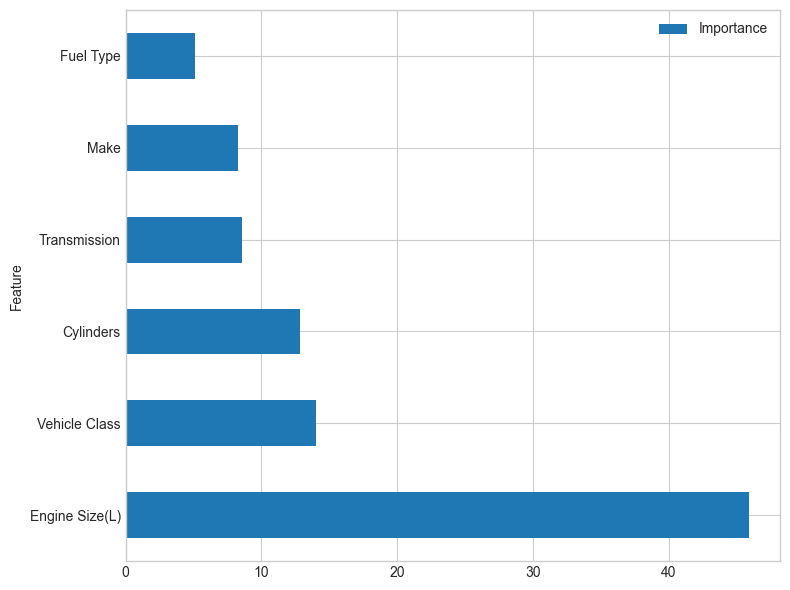

In [368]:
xgb_pi.drop('Std', axis=1).plot(kind='barh', figsize=(8, 6))
plt.tight_layout()
plt.show()

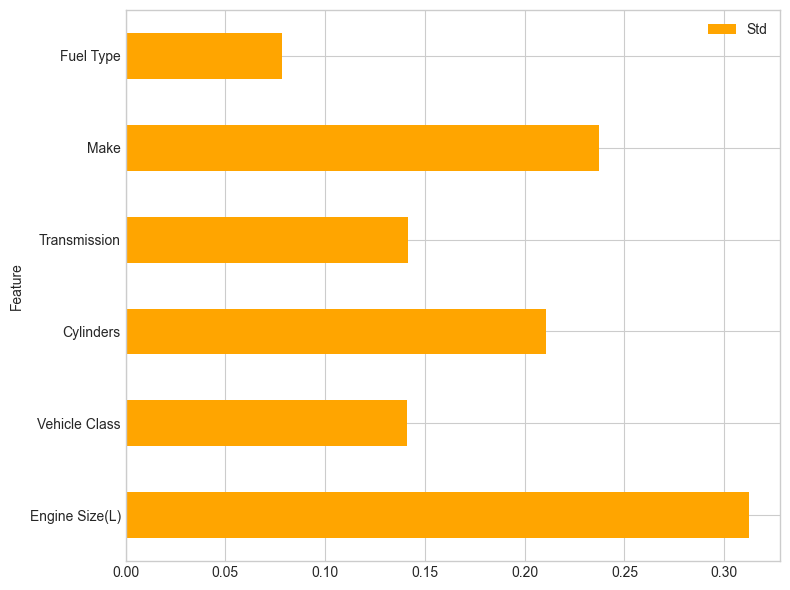

In [369]:
xgb_pi.drop('Importance', axis=1).plot(kind='barh', figsize=(8, 6), color='orange')
plt.tight_layout()
plt.show()

### 10.5.3 - Extra Trees

In [370]:
et_pi = compute_permutation_importance(
    model=best_et,
    X=X_train,
    y=y_train,
    feature_names=X_train.columns
)

In [371]:
et_pi

,Importance,Std
Feature,,
Engine Size(L),34.640926,0.244644
Vehicle Class,17.496601,0.190237
Cylinders,13.464605,0.188011
Make,9.812741,0.230305
Transmission,9.475824,0.132835
Fuel Type,8.476740,0.194019


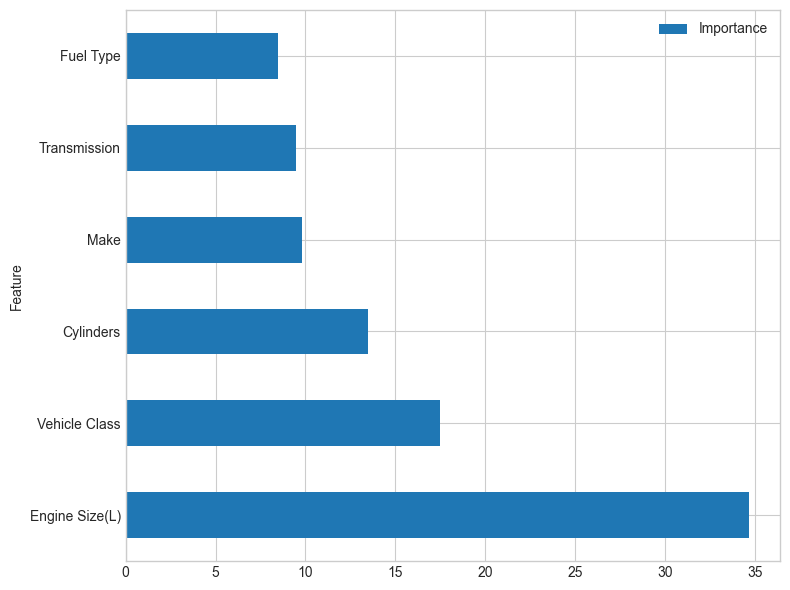

In [372]:
et_pi.drop('Std', axis=1).plot(kind='barh', figsize=(8, 6))
plt.tight_layout()
plt.show()

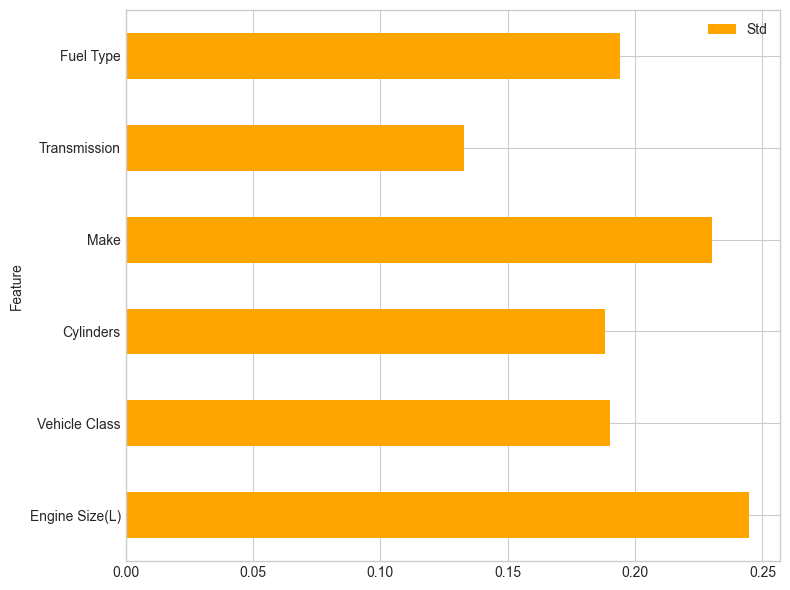

In [373]:
et_pi.drop('Importance', axis=1).plot(kind='barh', figsize=(8, 6), color='orange')
plt.tight_layout()
plt.show()

### 10.5.4 - Decision Tree

In [184]:
dt_pi = compute_permutation_importance(
    model=best_dt,
    X=X_train,
    y=y_train,
    feature_names=X_train.columns
)

In [185]:
et_pi

,Importance,Std
Feature,,
Engine Size(L),34.640926,0.244644
Vehicle Class,17.496601,0.190237
Cylinders,13.464605,0.188011
Make,9.812741,0.230305
Transmission,9.475824,0.132835
Fuel Type,8.476740,0.194019


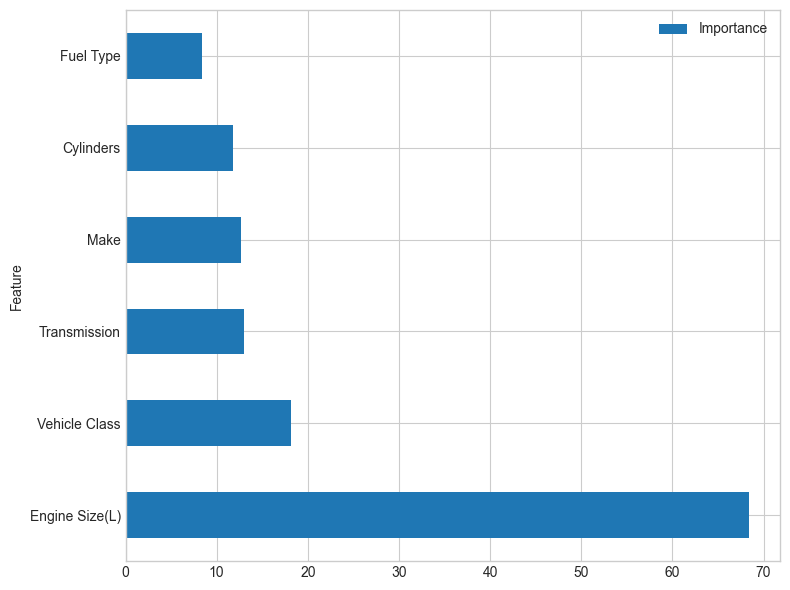

In [374]:
dt_pi.drop('Std', axis=1).plot(kind='barh', figsize=(8, 6))
plt.tight_layout()
plt.show()

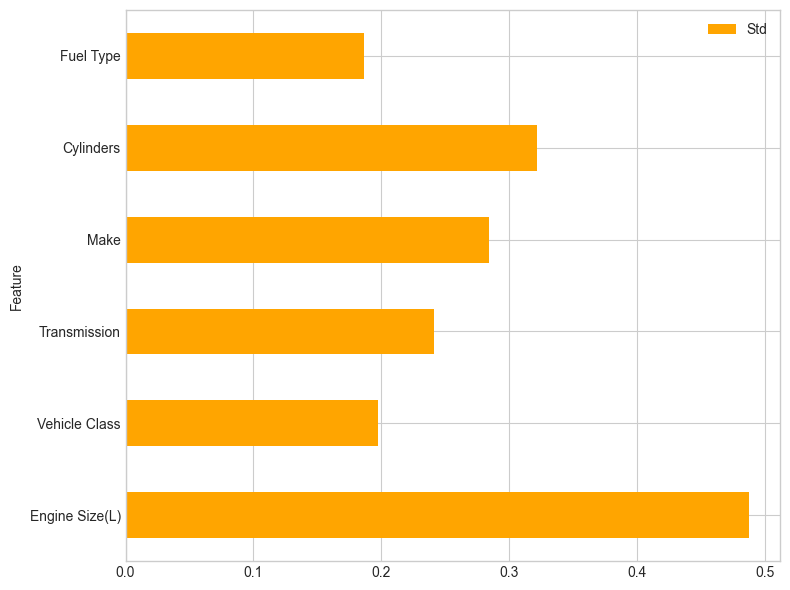

In [375]:
dt_pi.drop('Importance', axis=1).plot(kind='barh', figsize=(8, 6), color='orange')
plt.tight_layout()
plt.show()

# 11 - Final Model Selection

## 11.1 - Comparison Table

In [407]:
results = {
    "Random Forest": rf_results,
    "XGB": xgb_results,
    "Extra Trees": et_results,
    "Decision Tree": dt_results
}

In [408]:
final_results = {}

In [409]:
for name, value in results.items():
    final_results[name] = {}
    for key in value.keys():
        for metric in value[key]:
            final_results[name][f'Train {metric}' if key == 'Train' else f'Test {metric}'] = value[key][metric]

In [410]:
rmse_gaps = {
    name: round(
        (res['Test']['RMSE'] - res['Train']['RMSE']),
        3
    )
    for name, res in results.items()
}

In [411]:
mean_cv_scores = {
    "Random Forest": round(-search_rf.best_score_, 3), 
    'XGB': round(-search_xgb.best_score_, 3),
    'Extra Trees': round(-search_et.best_score_, 3),
    'Decision Tree': round(-search_dt.best_score_, 3)
}

In [414]:
idx = search_rf.best_index_

std_cv_scores = {
    'Random Forest': round(search_rf.cv_results_['std_test_score'][idx], 2),
    'XGB': round(search_xgb.cv_results_['std_test_score'][idx], 2),
    'Extra Trees': round(search_et.cv_results_['std_test_score'][idx], 2),
    'Decision Tree': round(search_dt.cv_results_['std_test_score'][idx], 2),
}

In [415]:
for key in final_results.keys():
    final_results[key]['Std CV RMSE'] = std_cv_scores[key]
    final_results[key]['Mean CV RMSE'] = mean_cv_scores[key]
    final_results[key]['RMSE Gap'] = rmse_gaps[key]

In [416]:
final_results = pd.DataFrame(final_results).T

In [417]:
def highlight_winners(df, directions):
    styles = pd.DataFrame("", index=df.index, columns=df.columns)

    for col, direction in directions.items():

        if direction == "max":
            winner_idx = df[col].idxmax()

        elif direction == "min":
            winner_idx = df[col].idxmin()

        styles.loc[winner_idx, col] = (
            "color: green; font-weight: bold"
        )

    return styles

In [419]:
directions = {
    "Train R$^2$": "max",
    'Train MAE': 'min',
    'Train RMSE': 'min',
    'Test R$^2$': 'max',
    "Test MAE": "min",
    "Test RMSE": "min",
    'Std CV RMSE': 'min',
    'Mean CV RMSE': "min",
    "Test RMSE Gap": "min"
}

In [420]:
final_results.columns = directions.keys()

In [421]:
final_results.style.apply(highlight_winners, axis=None, directions=directions)

,Train R$^2$,Train MAE,Train RMSE,Test R$^2$,Test MAE,Test RMSE,Std CV RMSE,Mean CV RMSE,Test RMSE Gap
Random Forest,0.970000,6.808000,10.308000,0.948000,9.365000,13.444000,0.540000,13.590000,3.136000
XGB,0.968000,7.486000,10.666000,0.950000,9.311000,13.163000,0.490000,13.400000,2.497000
Extra Trees,0.968000,7.484000,10.696000,0.946000,9.518000,13.618000,0.640000,13.840000,2.922000
Decision Tree,0.967000,7.418000,10.826000,0.945000,9.705000,13.728000,3.580000,14.714000,2.902000


## 11.2 - Selection Criteria

The final model is selected based on the following criteria:

1. Lower cross-validated RMSE is preferred as the primary criterion.
2. MAE and R$^2$ are used as secondary performance metrics.
3. Model stability across cross-validation folds is considered.
4. Residual and parity plots are examined to identify systematic errors.
5. If models show comparable predictive performance, the simpler and more practical model is preferred.

## 11.3 - Final Decision

- Based on the evaluation criteria, XGBRegressor achieved the lowest cross-validation RMSE among the evaluated models.

- However, model selection was not based solely on RMSE. MAE, R$^2$, cross-validation stability, and diagnostics analyses were also considered.

- Overall, XGB provided the best balance of predictive performance and generalization and was therefore selected as the final model.

# 12 - Final Evaluation & Interpretation   

In [357]:
final_model = best_xgb
final_model_name = 'XGBRegressor'

## 12.1 - Final Test Metrics

In [358]:
xgb_test_results = pd.DataFrame(final_results.loc['XGB', :]).T[['Test RMSE', 'Test MAE', 'Test R$^2$']]

In [359]:
xgb_test_results

,Test RMSE,Test MAE,Test R$^2$
XGB,13.163,9.311,0.95


## 12.2 - Final Residual Plot

In [393]:
final_model_resp = plot_residual(
    model=final_model,
    model_name=final_model_name,
    X=X_test,
    y=y_test
)

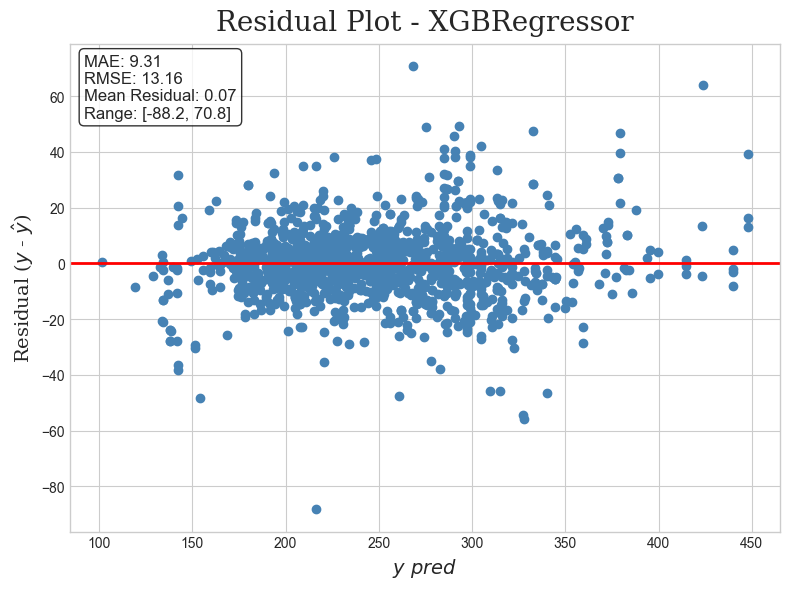

In [394]:
final_model_resp

## 12.3 - Final Parity Plot

In [362]:
final_model_parityp = plot_praity(
    model=final_model,
    model_name=final_model_name,
    X=X_test,
    y=y_test
)

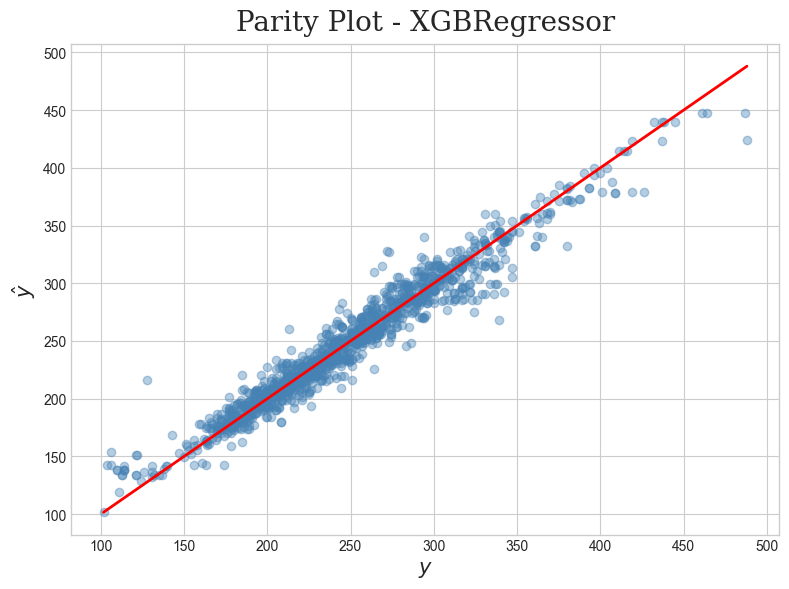

In [363]:
final_model_parityp

## 12.4 - Final Permutatoin Importance

In [364]:
final_model_permutation_importance = compute_permutation_importance(
    model=final_model,
    X=X_test,
    y=y_test,
    feature_names=X_test.columns
)

In [365]:
final_model_permutation_importance

,Importance,Std
Feature,,
Engine Size(L),42.703398,0.559852
Vehicle Class,11.314561,0.399763
Cylinders,10.865490,0.263659
Transmission,8.037224,0.251328
Make,6.383021,0.261722
Fuel Type,4.649978,0.294363


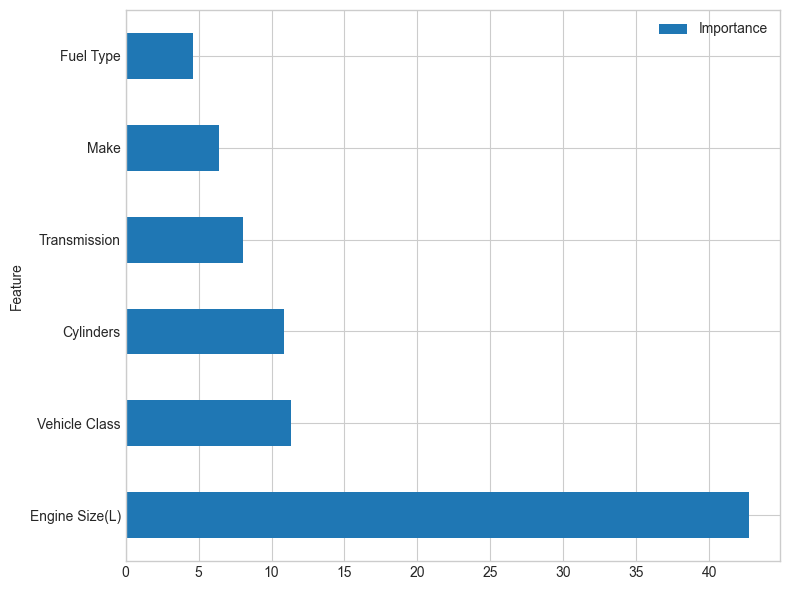

In [376]:
final_model_permutation_importance.drop('Std', axis=1).plot(kind='barh', figsize=(8, 6))
plt.tight_layout()
plt.show()

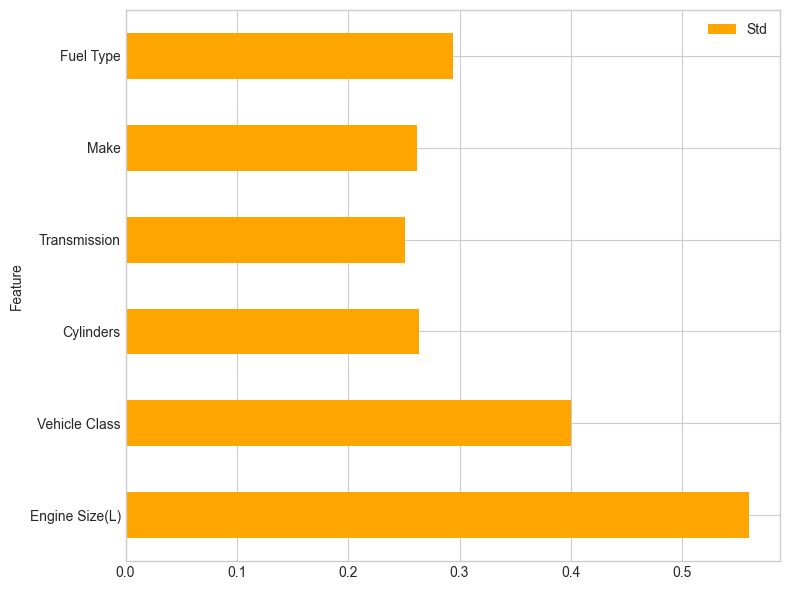

In [377]:
final_model_permutation_importance.drop('Importance', axis=1).plot(kind='barh', figsize=(8, 6), color='orange')
plt.tight_layout()
plt.show()

## 12.5 - Interpretation

- Test RMSE indicates the root mean squared error of the model's predictions on the test set. A value of 13.163 g/km means that the model's prediction errors have an RMSE of 13.163 g/km.
- Test MAE indicates the mean absolute error of the model's predictions on the test set. A value of 9.311 g/km means that the model's predictions differ from the actual values by 9.311 g/km on average, in absolute terms.
- Test R$^2$ indicates the proportion of variance in the target variable that is explained by the model on the test set. A value of 0.95 (95%) means that the model explains approximately 95% of the variance in the target variable on the test set.

- Residuals ($y$-$\hat{y}$) represent the prediction errors, where ($y$) is the actual value and ($\hat{y}$) is the predicted value. A residual plot shows the residuals against the predicted values. As observed in the residual plot of the final model on the test set, the residuals were roughly patternless, suggesting no obvious systematic pattern in the prediction errors.
  
- A parity plot shows the actual values against the predicted values. In the parity plot of the final model on the test set, the points were approximately distributed around the ($y=x$) line, indicating that the predicted values were generally close to the actual values.
- Permutation Importance measures the importance of each feature by evaluating the decrease in model performance when the values of that feature are randomly shuffled. A larger performance decrease indicates that the model relies more heavily on that feature for its predictions.

# 13 - Conclusions & Limitations